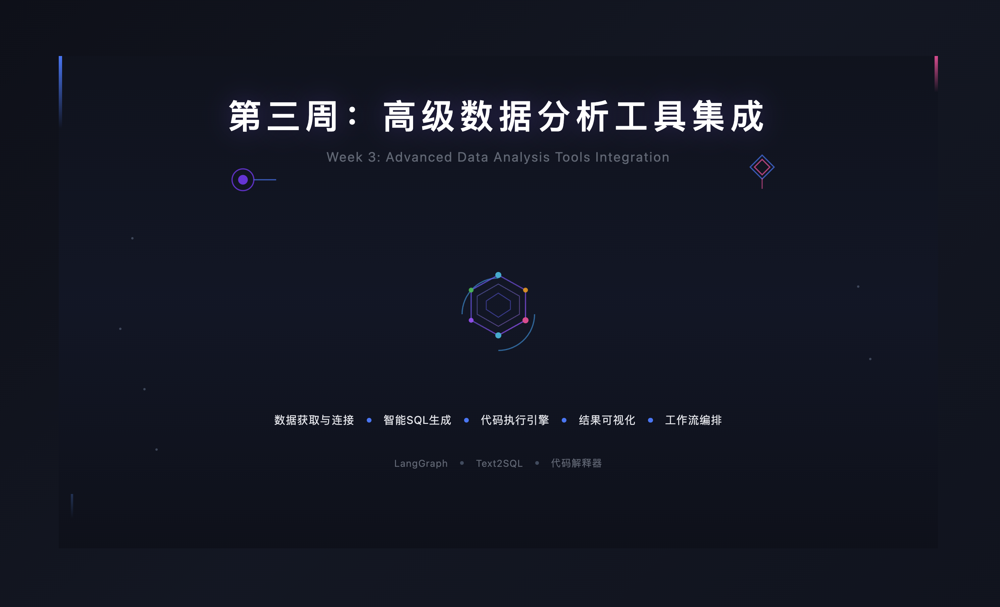

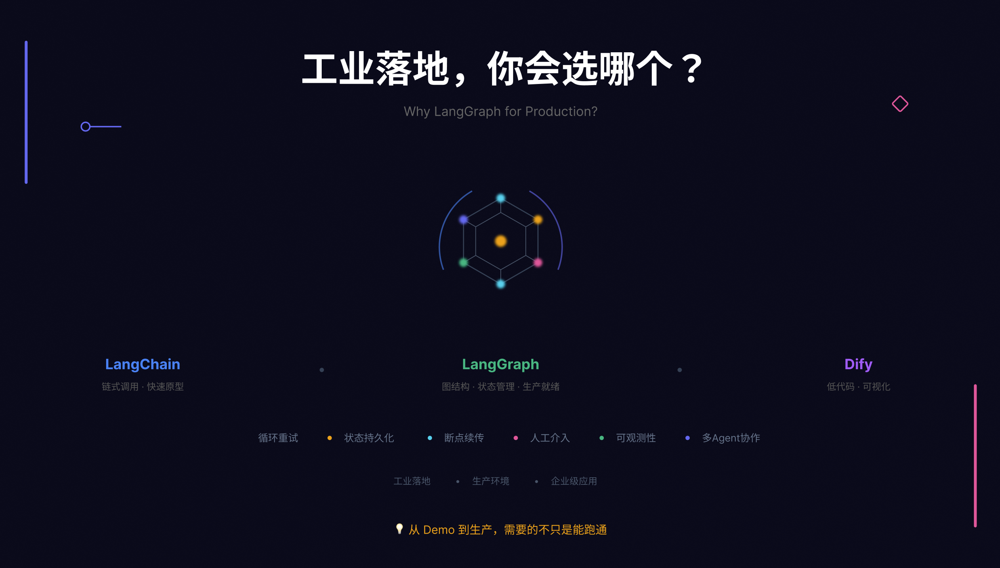

# 一.LangGraph 从零到精通完全指南
本章节将带你从零开始，循序渐进地掌握 LangGraph，让你能够构建强大的 AI Agent 应用。

---
目录
1. LangGraph 是什么？
2. 核心概念详解
3. 环境搭建
4. 第一个 LangGraph 程序
5. 状态管理深入理解
6. 条件边与流程控制
7. 集成 LLM 构建聊天机器人
8. 工具调用 (Tool Calling)
9. 构建完整的 ReAct Agent
10. 人机协作 (Human-in-the-Loop)
11. 持久化与记忆

# 1. LangGraph 是什么？
## 1.1 定义
LangGraph 是 LangChain 团队开发的一个低层级编排框架，专门用于构建有状态的、多参与者的 LLM 应用程序。它的核心思想是将应用程序的工作流表示为**图（Graph）**结构。
## 1.2 为什么需要 LangGraph？
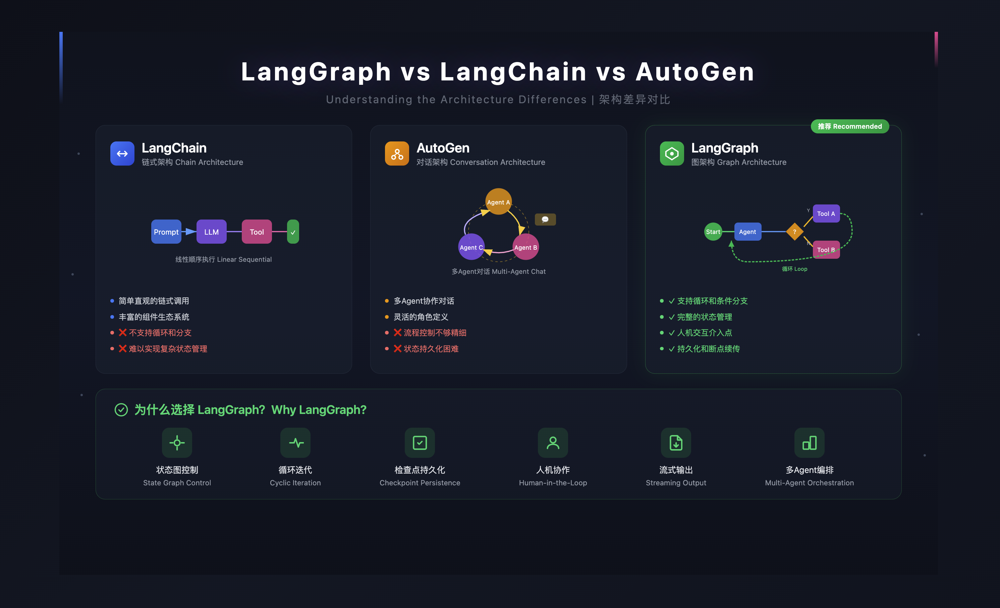

# 一个Agent框架的可测试性非常重要！


# 2. 核心概念详解

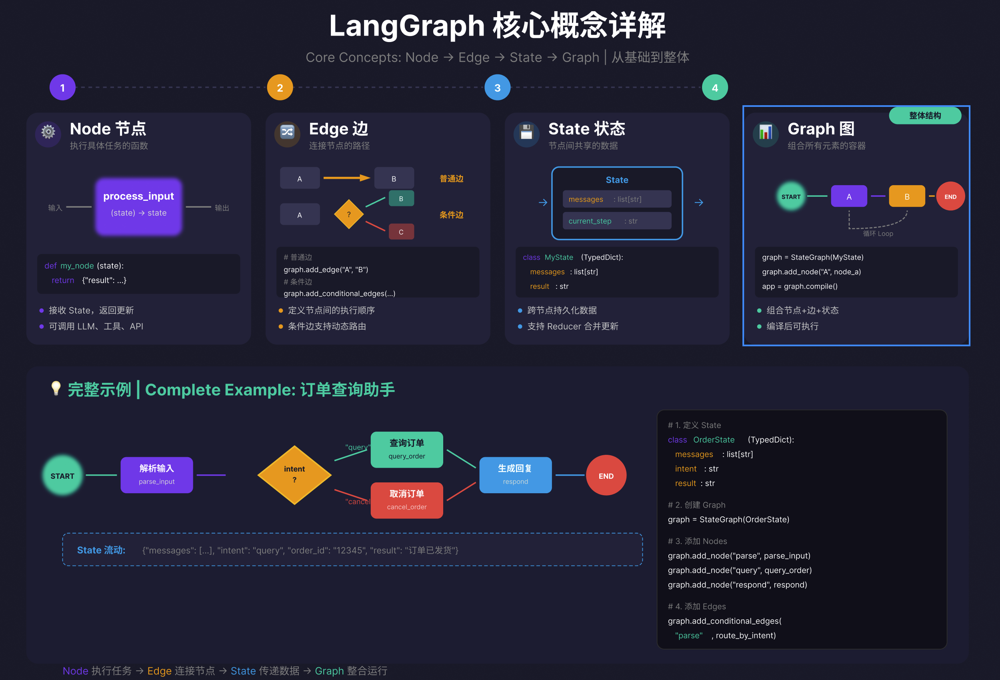

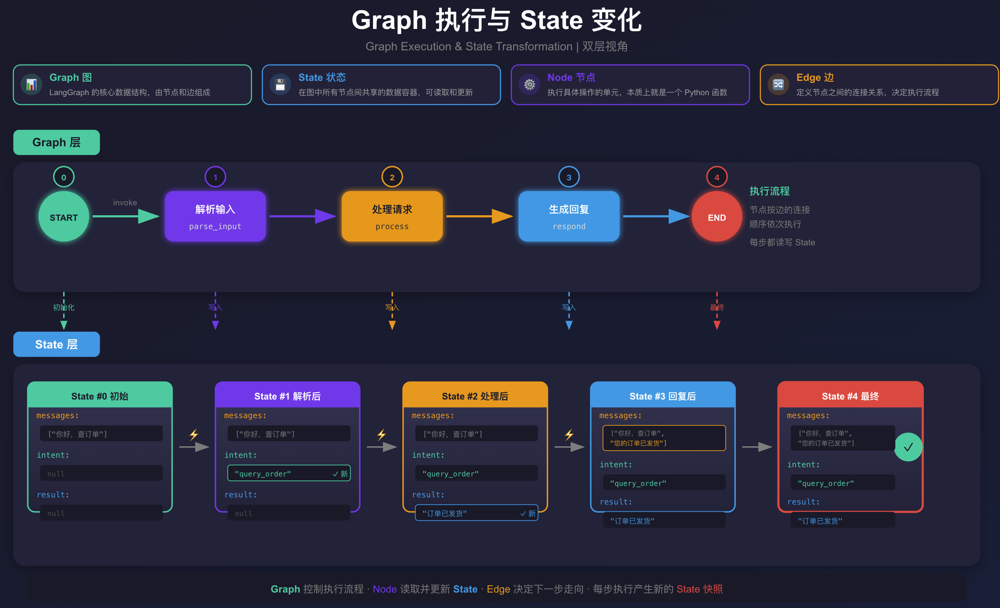

## 2.1 State状态

In [92]:
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages

# 简单状态
class SimpleState(TypedDict):
    user_input: str
    result: str

# 带 Reducer 的状态 (推荐)
class ChatState(TypedDict):
    messages: Annotated[list, add_messages]  # 自动追加
    context: dict

## 2.2 节点Node

In [93]:
from langgraph.graph import StateGraph, START, END
# 2. 定义节点函数（实际执行的代码）
def agent_function(state: ChatState) -> dict:
    """这是 agent 节点实际执行的函数"""
    return {"messages": ["Agent: 我在思考..."]}

def tool_function(state: ChatState) -> dict:
    """这是 tool 节点实际执行的函数"""
    return {"messages": ["Tool: 搜索完成"]}

# 3. 创建图
graph = StateGraph(ChatState)

# 4. ⭐ 添加节点：把名称和函数关联起来
graph.add_node("agent", agent_function)  # "agent" 是名称，agent_function 是函数
graph.add_node("tool", tool_function)    # "tool" 是名称，tool_function 是函数

## 2.3 边Edge

In [94]:
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages


# ① 普通边
graph.add_edge(START, "agent")        # START → agent
graph.add_edge("agent", "tool")       # agent → tool
graph.add_edge("tool", END)           # tool → END

# ② 条件边
def should_continue(state: ChatState) -> str:
    """路由函数: 返回下一个节点名"""
    last_msg = state["messages"][-1]
    if hasattr(last_msg, "tool_calls") and last_msg.tool_calls:
        return "tool"
    return "end"

graph.add_conditional_edges(
    "agent",                # 源节点
    should_continue,        # 路由函数
    {
        "tool": "tool",     # 返回 "tool" → 去 tool 节点
        "end": END          # 返回 "end" → 结束
    }
)

# ③ 循环边 (tool 执行后回到 agent)
graph.add_edge("tool", "agent")

## 2.4 图Graph

In [95]:
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

# 1. 定义状态
class ChatState(TypedDict):
    messages: Annotated[list, add_messages]

# 2. 定义节点函数（实际执行的代码）
def agent_function(state: ChatState) -> dict:
    """这是 agent 节点实际执行的函数"""
    return {"messages": ["Agent: 我在思考..."]}

def tool_function(state: ChatState) -> dict:
    """这是 tool 节点实际执行的函数"""
    return {"messages": ["Tool: 搜索完成"]}

# 3. 创建图
graph = StateGraph(ChatState)

# 4. ⭐ 添加节点：把名称和函数关联起来
graph.add_node("agent", agent_function)  # "agent" 是名称，agent_function 是函数
graph.add_node("tool", tool_function)    # "tool" 是名称，tool_function 是函数

# 5. 添加边（现在才能用 "agent" 和 "tool"）
graph.add_edge(START, "agent")
graph.add_edge("agent", "tool")
graph.add_edge("tool", END)

# 6. 编译运行
app = graph.compile()
result = app.invoke({"messages": ["你好"]})
print(result["messages"])

[HumanMessage(content='你好', additional_kwargs={}, response_metadata={}, id='38e53914-0f04-436a-a9a7-7e1ac29cda15'), HumanMessage(content='Agent: 我在思考...', additional_kwargs={}, response_metadata={}, id='51add8a5-2ba8-49f6-9c27-e1af267b2391'), HumanMessage(content='Tool: 搜索完成', additional_kwargs={}, response_metadata={}, id='0a8465b5-6a4f-4771-81fe-2e9208e23334')]


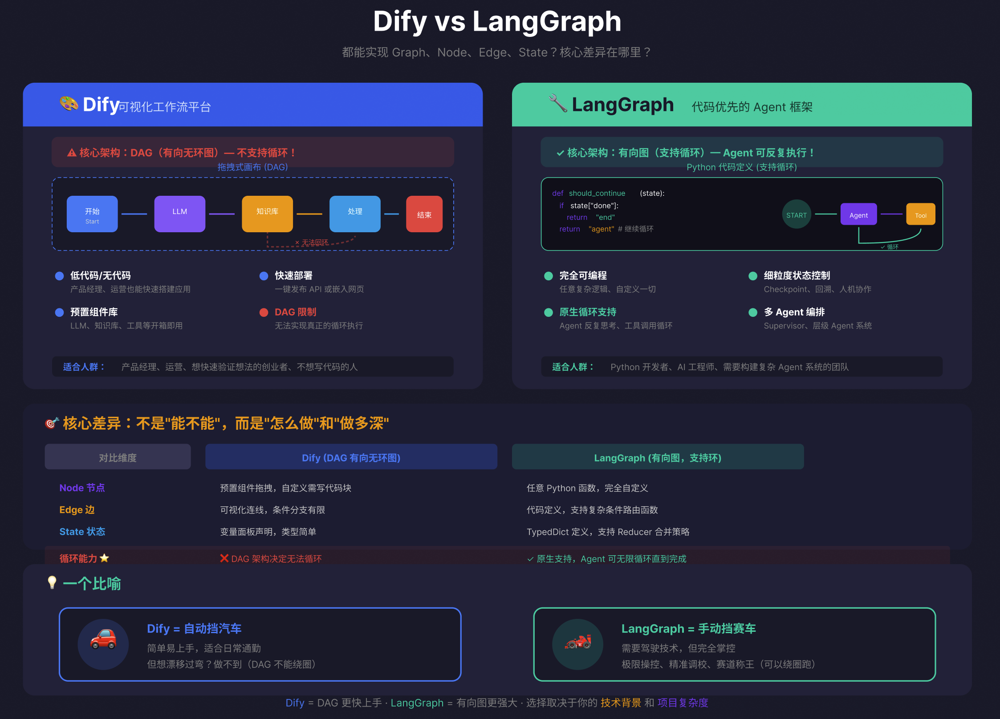

# 3.环境搭建

In [68]:
from dotenv import load_dotenv
load_dotenv()

True

In [69]:
#   # 用 Docker 一键部署
#   git clone https://github.com/langfuse/langfuse.git
#   cd langfuse
#   docker compose up -d

#   然后访问 http://localhost:3000 创建账号并获取 API Key。

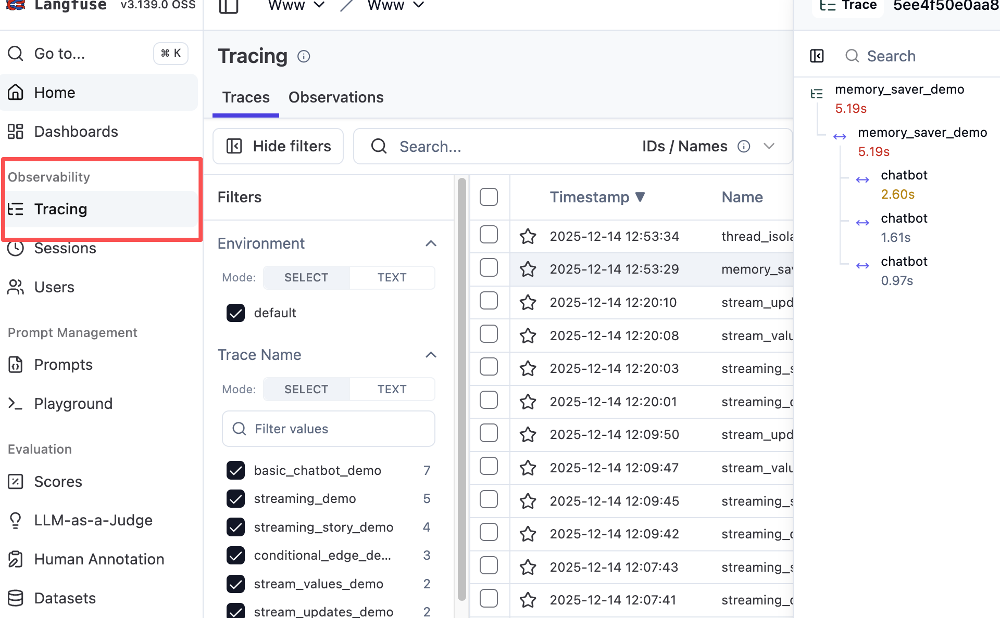

# 4.一个简单的例子

In [96]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END

class ProcessState(TypedDict):
    numbers: List[int]
    doubled: List[int]
    total: int

def double_numbers(state: ProcessState) -> dict:
    """将所有数字翻倍"""
    doubled = [n * 2 for n in state["numbers"]]
    return {"doubled": doubled}

def calculate_sum(state: ProcessState) -> dict:
    """计算总和"""
    total = sum(state["doubled"])
    return {"total": total}

# 创建并配置图
graph = StateGraph(ProcessState)
graph.add_node("double", double_numbers)
graph.add_node("sum", calculate_sum)

graph.add_edge(START, "double")
graph.add_edge("double", "sum")
graph.add_edge("sum", END)

app = graph.compile()

# 运行
result = app.invoke({
    "numbers": [1, 2, 3, 4, 5],
    "doubled": [],
    "total": 0
})

print(f"原始数字: {result['numbers']}")      # [1, 2, 3, 4, 5]
print(f"翻倍后: {result['doubled']}")        # [2, 4, 6, 8, 10]
print(f"总和: {result['total']}")            # 30

原始数字: [1, 2, 3, 4, 5]
翻倍后: [2, 4, 6, 8, 10]
总和: 30


## 5.用langfuse监控过程

Agent架构设计时候的可测试、可监控

In [97]:
from langfuse import observe, Langfuse

# 查看 observe
print(type(observe))

<class 'method'>


In [98]:
import os
from langfuse import observe, Langfuse
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END

# 1. 设置环境变量
from dotenv import load_dotenv
load_dotenv()

# 2. 定义状态
class ProcessState(TypedDict):
    numbers: List[int]
    doubled: List[int]
    total: int

# 3. 用 @observe 装饰节点函数
@observe()
def double_numbers(state: ProcessState) -> dict:
    doubled = [n * 2 for n in state["numbers"]]
    return {"doubled": doubled}

@observe()
def calculate_sum(state: ProcessState) -> dict:
    total = sum(state["doubled"])
    return {"total": total}

# 4. 创建图
graph = StateGraph(ProcessState)
graph.add_node("double", double_numbers)
graph.add_node("sum", calculate_sum)
graph.add_edge(START, "double")
graph.add_edge("double", "sum")
graph.add_edge("sum", END)
app = graph.compile()

# 5. 用 @observe 包装整个运行
@observe()
def run_pipeline(numbers: List[int]):
    result = app.invoke({
        "numbers": numbers,
        "doubled": [],
        "total": 0
    })
    return result

# 6. 执行
result = run_pipeline([1, 2, 3, 4, 5])
print(f"原始: {result['numbers']}")
print(f"翻倍: {result['doubled']}")
print(f"总和: {result['total']}")

# 7. 确保数据上传
langfuse = Langfuse()
langfuse.flush()

原始: [1, 2, 3, 4, 5]
翻倍: [2, 4, 6, 8, 10]
总和: 30


## 6.状态管理深入理解

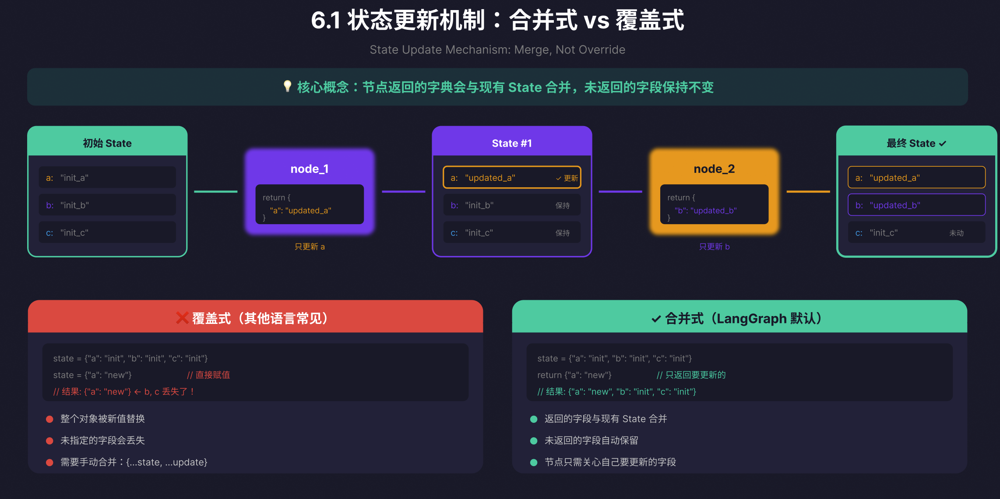

In [99]:
"""
6.1 状态更新机制：合并式 vs 覆盖式
State Update Mechanism: Merge, Not Override

LangGraph 的状态更新是合并式的，不是覆盖式的。
节点只需返回要更新的字段，其他字段会自动保留。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv()

# 导入依赖
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 定义 State

# %%
class State(TypedDict):
    a: str
    b: str
    c: str

print("State 结构:")
print("  a: str")
print("  b: str")
print("  c: str")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="node_1")
def node_1(state: State) -> dict:
    """
    只更新字段 a，其他字段保持不变
    """
    print(f"node_1 收到: {state}")
    
    # 只返回要更新的字段
    result = {"a": "updated_a"}
    
    print(f"node_1 返回: {result}")
    return result


@observe(name="node_2")
def node_2(state: State) -> dict:
    """
    只更新字段 b，其他字段保持不变
    """
    print(f"node_2 收到: {state}")
    
    # 只返回要更新的字段
    result = {"b": "updated_b"}
    
    print(f"node_2 返回: {result}")
    return result

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(State)

# 添加节点
graph.add_node("node_1", node_1)
graph.add_node("node_2", node_2)

# 添加边
graph.add_edge(START, "node_1")
graph.add_edge("node_1", "node_2")
graph.add_edge("node_2", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 执行演示

# %%
# 初始状态
initial_state = {
    "a": "init_a",
    "b": "init_b",
    "c": "init_c"
}

print("=" * 50)
print("6.1 状态更新机制演示")
print("=" * 50)
print(f"\n初始状态: {initial_state}")
print("\n执行流程:")
print("-" * 30)

# 执行图
result = app.invoke(initial_state)

print("-" * 30)
print(f"\n最终状态: {result}")

# 验证结果
print("\n验证:")
print(f"  a: 'init_a' -> '{result['a']}' (被 node_1 更新)")
print(f"  b: 'init_b' -> '{result['b']}' (被 node_2 更新)")
print(f"  c: 'init_c' -> '{result['c']}' (未被任何节点修改，保持原值)")

# %% [markdown]
# ## 6. 发送 Langfuse 数据

# %%
# 确保 Langfuse 数据被发送
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
State 结构:
  a: str
  b: str
  c: str
✓ 节点函数定义完成
✓ 图构建完成
6.1 状态更新机制演示

初始状态: {'a': 'init_a', 'b': 'init_b', 'c': 'init_c'}

执行流程:
------------------------------
node_1 收到: {'a': 'init_a', 'b': 'init_b', 'c': 'init_c'}
node_1 返回: {'a': 'updated_a'}
node_2 收到: {'a': 'updated_a', 'b': 'init_b', 'c': 'init_c'}
node_2 返回: {'b': 'updated_b'}
------------------------------

最终状态: {'a': 'updated_a', 'b': 'updated_b', 'c': 'init_c'}

验证:
  a: 'init_a' -> 'updated_a' (被 node_1 更新)
  b: 'init_b' -> 'updated_b' (被 node_2 更新)
  c: 'init_c' -> 'init_c' (未被任何节点修改，保持原值)

✓ 执行完成，数据已发送到 Langfuse 监控


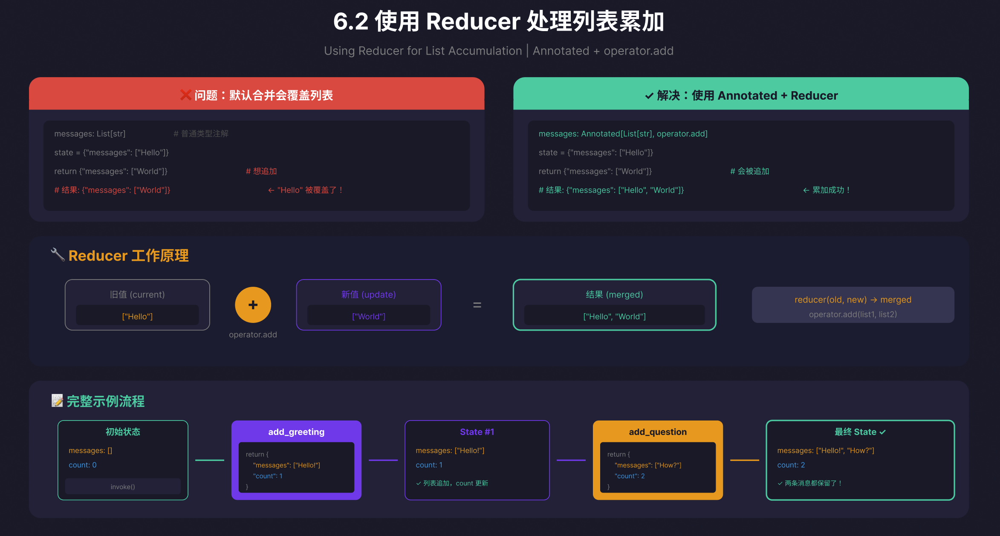

In [100]:
"""
6.2 使用 Reducer 处理列表累加
Using Reducer for List Accumulation

当你需要将新数据追加到列表而不是覆盖时，需要使用 Reducer。
通过 Annotated 和 operator.add 实现列表的累加效果。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv()

# 导入依赖
from typing import TypedDict, List, Annotated
import operator
from langgraph.graph import StateGraph, START, END
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 定义 State（使用 Reducer）

# %%
class State(TypedDict):
    # 使用 Annotated 和 operator.add 作为 reducer
    # 这样每次返回的列表会被追加，而不是覆盖
    messages: Annotated[List[str], operator.add]
    count: int

print("State 结构:")
print("  messages: Annotated[List[str], operator.add]  ← 使用 Reducer!")
print("  count: int")
print("\n关键: operator.add 会将新列表追加到旧列表")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="add_greeting")
def add_greeting(state: State) -> dict:
    """添加问候语到消息列表"""
    print(f"add_greeting 收到: messages={state['messages']}, count={state['count']}")
    
    result = {
        "messages": ["Hello!"],  # 会被追加到现有列表
        "count": state["count"] + 1
    }
    
    print(f"add_greeting 返回: {result}")
    return result


@observe(name="add_question")
def add_question(state: State) -> dict:
    """添加问题到消息列表"""
    print(f"add_question 收到: messages={state['messages']}, count={state['count']}")
    
    result = {
        "messages": ["How are you?"],  # 继续追加
        "count": state["count"] + 1
    }
    
    print(f"add_question 返回: {result}")
    return result


@observe(name="add_farewell")
def add_farewell(state: State) -> dict:
    """添加告别语到消息列表"""
    print(f"add_farewell 收到: messages={state['messages']}, count={state['count']}")
    
    result = {
        "messages": ["Goodbye!"],  # 继续追加
        "count": state["count"] + 1
    }
    
    print(f"add_farewell 返回: {result}")
    return result

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(State)

# 添加节点
graph.add_node("greeting", add_greeting)
graph.add_node("question", add_question)
graph.add_node("farewell", add_farewell)

# 添加边
graph.add_edge(START, "greeting")
graph.add_edge("greeting", "question")
graph.add_edge("question", "farewell")
graph.add_edge("farewell", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 执行演示

# %%
# 初始状态
initial_state = {
    "messages": [],  # 空列表
    "count": 0
}

print("=" * 60)
print("6.2 Reducer 列表累加演示")
print("=" * 60)
print(f"\n初始状态: {initial_state}")
print("\n执行流程:")
print("-" * 40)

# 执行图
result = app.invoke(initial_state)

print("-" * 40)
print(f"\n最终状态:")
print(f"  messages: {result['messages']}")
print(f"  count: {result['count']}")

# 验证结果
print("\n验证 Reducer 效果:")
print("  每个节点返回的 messages 都被追加，而不是覆盖:")
for i, msg in enumerate(result['messages'], 1):
    print(f"    {i}. \"{msg}\"")

# 对比：如果没有 Reducer
print("\n对比（如果没有 Reducer）:")
print("  最后一个节点返回 ['Goodbye!']")
print("  结果会是: messages=['Goodbye!'] ← 前面的消息丢失！")

# %% [markdown]
# ## 6. 发送 Langfuse 数据

# %%
# 确保 Langfuse 数据被发送
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
State 结构:
  messages: Annotated[List[str], operator.add]  ← 使用 Reducer!
  count: int

关键: operator.add 会将新列表追加到旧列表
✓ 节点函数定义完成
✓ 图构建完成
6.2 Reducer 列表累加演示

初始状态: {'messages': [], 'count': 0}

执行流程:
----------------------------------------
add_greeting 收到: messages=[], count=0
add_greeting 返回: {'messages': ['Hello!'], 'count': 1}
add_question 收到: messages=['Hello!'], count=1
add_question 返回: {'messages': ['How are you?'], 'count': 2}
add_farewell 收到: messages=['Hello!', 'How are you?'], count=2
add_farewell 返回: {'messages': ['Goodbye!'], 'count': 3}
----------------------------------------

最终状态:
  messages: ['Hello!', 'How are you?', 'Goodbye!']
  count: 3

验证 Reducer 效果:
  每个节点返回的 messages 都被追加，而不是覆盖:
    1. "Hello!"
    2. "How are you?"
    3. "Goodbye!"

对比（如果没有 Reducer）:
  最后一个节点返回 ['Goodbye!']
  结果会是: messages=['Goodbye!'] ← 前面的消息丢失！

✓ 执行完成，数据已发送到 Langfuse 监控


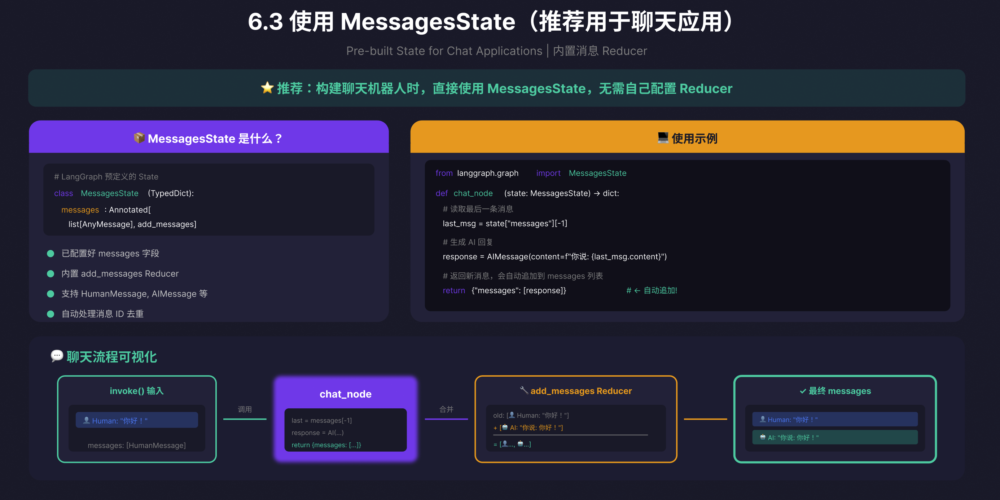

In [101]:
"""
6.3 使用 MessagesState（推荐用于聊天应用）
Using MessagesState for Chat Applications

LangGraph 提供了预定义的 MessagesState，专门用于处理消息历史。
内置了 add_messages reducer，自动处理消息追加和去重。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv()

# 导入依赖
from langgraph.graph import MessagesState, StateGraph, START, END
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 了解 MessagesState

# %%
# MessagesState 已经内置了 messages 字段和正确的 reducer
# 等价于：
# class MessagesState(TypedDict):
#     messages: Annotated[list[AnyMessage], add_messages]

print("MessagesState 特点:")
print("  ✓ 内置 messages 字段")
print("  ✓ 内置 add_messages reducer")
print("  ✓ 支持 HumanMessage, AIMessage, SystemMessage 等")
print("  ✓ 自动处理消息 ID 去重")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="process_input")
def process_input(state: MessagesState) -> dict:
    """处理用户输入，生成系统分析"""
    messages = state["messages"]
    last_message = messages[-1]
    
    print(f"process_input: 收到用户消息 - \"{last_message.content}\"")

    # 添加一条系统处理消息
    system_note = AIMessage(
        content=f"[系统] 正在处理您的请求: {last_message.content}"
    )
    
    return {"messages": [system_note]}  # 会自动追加


@observe(name="generate_response")
def generate_response(state: MessagesState) -> dict:
    """生成 AI 回复"""
    messages = state["messages"]
    
    # 找到用户的原始消息（第一条 HumanMessage）
    user_messages = [m for m in messages if isinstance(m, HumanMessage)]
    original_query = user_messages[-1].content if user_messages else "未知请求"
    
    print(f"generate_response: 生成回复...")
    
    # 生成回复
    response = AIMessage(
        content=f"您好！您说的是「{original_query}」。我是 AI 助手，很高兴为您服务！"
    )
    
    return {"messages": [response]}  # 会自动追加


@observe(name="add_followup")
def add_followup(state: MessagesState) -> dict:
    """添加后续提示"""
    print(f"add_followup: 添加后续提示...")
    
    followup = AIMessage(
        content="还有什么我可以帮助您的吗？"
    )
    
    return {"messages": [followup]}  # 会自动追加

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(MessagesState)

# 添加节点
graph.add_node("process", process_input)
graph.add_node("respond", generate_response)
graph.add_node("followup", add_followup)

# 添加边
graph.add_edge(START, "process")
graph.add_edge("process", "respond")
graph.add_edge("respond", "followup")
graph.add_edge("followup", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 执行演示

# %%
# 初始状态：用户发送一条消息
initial_state = {
    "messages": [
        HumanMessage(content="你好，我想了解 LangGraph！")
    ]
}

print("=" * 60)
print("6.3 MessagesState 演示")
print("=" * 60)

print(f"\n初始消息:")
for msg in initial_state["messages"]:
    print(f"  [{msg.type}] {msg.content}")

print("\n执行流程:")
print("-" * 40)

# 执行图
result = app.invoke(initial_state)

print("-" * 40)
print(f"\n最终消息列表 ({len(result['messages'])} 条):")
for i, msg in enumerate(result["messages"], 1):
    msg_type = msg.type.upper()
    prefix = "👤" if msg_type == "HUMAN" else "🤖"
    print(f"  {i}. {prefix} [{msg_type}] {msg.content}")

# 验证消息累加
print("\n验证:")
print(f"  初始: 1 条消息")
print(f"  最终: {len(result['messages'])} 条消息")
print(f"  所有消息都被保留，新消息自动追加")

# %% [markdown]
# ## 6. 发送 Langfuse 数据

# %%
# 确保 Langfuse 数据被发送
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
MessagesState 特点:
  ✓ 内置 messages 字段
  ✓ 内置 add_messages reducer
  ✓ 支持 HumanMessage, AIMessage, SystemMessage 等
  ✓ 自动处理消息 ID 去重
✓ 节点函数定义完成
✓ 图构建完成
6.3 MessagesState 演示

初始消息:
  [human] 你好，我想了解 LangGraph！

执行流程:
----------------------------------------
process_input: 收到用户消息 - "你好，我想了解 LangGraph！"
generate_response: 生成回复...
add_followup: 添加后续提示...
----------------------------------------

最终消息列表 (4 条):
  1. 👤 [HUMAN] 你好，我想了解 LangGraph！
  2. 🤖 [AI] [系统] 正在处理您的请求: 你好，我想了解 LangGraph！
  3. 🤖 [AI] 您好！您说的是「你好，我想了解 LangGraph！」。我是 AI 助手，很高兴为您服务！
  4. 🤖 [AI] 还有什么我可以帮助您的吗？

验证:
  初始: 1 条消息
  最终: 4 条消息
  所有消息都被保留，新消息自动追加

✓ 执行完成，数据已发送到 Langfuse 监控


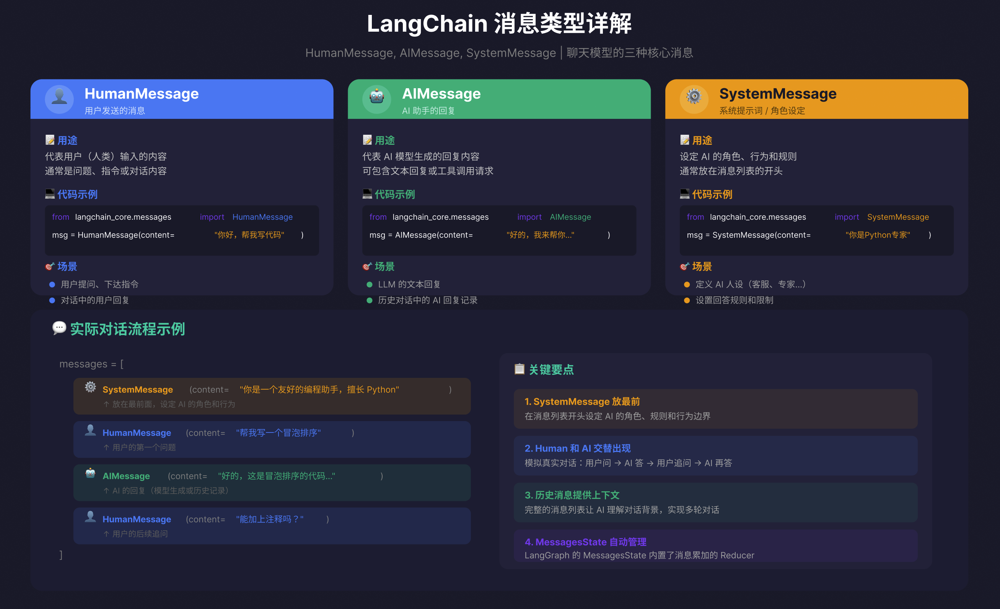

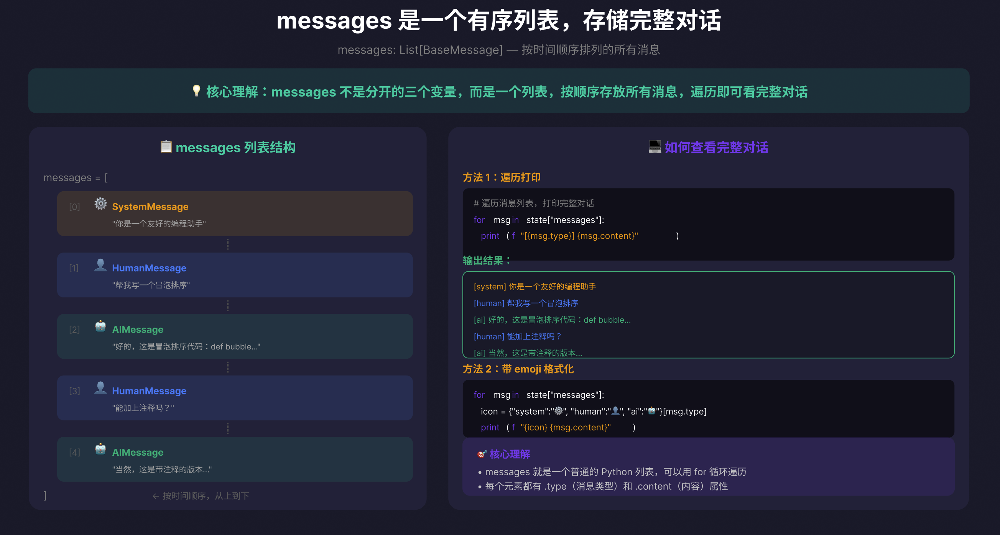

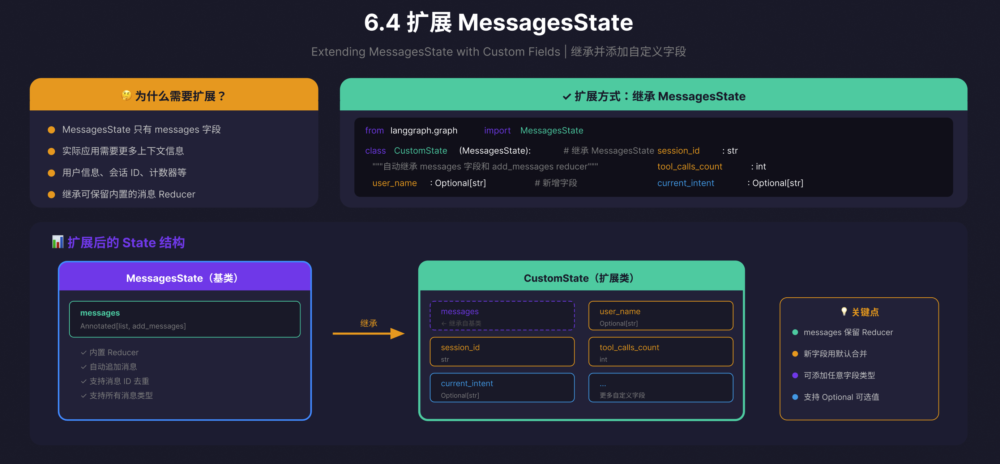

In [102]:
"""
6.4 扩展 MessagesState
Extending MessagesState with Custom Fields

继承 MessagesState 添加自定义字段，同时保留内置的消息 Reducer。
适用于需要更多上下文信息的聊天应用。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv()

# 导入依赖
from typing import Optional
from langgraph.graph import MessagesState, StateGraph, START, END
from langchain_core.messages import HumanMessage, AIMessage
from langfuse import observe, Langfuse
import uuid
from datetime import datetime

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 定义扩展的 State

# %%
class CustomState(MessagesState):
    """
    扩展 MessagesState，添加自定义字段
    
    继承自 MessagesState，自动获得:
    - messages 字段
    - add_messages reducer
    
    新增字段使用默认的合并更新策略
    """
    user_name: Optional[str]          # 用户名
    session_id: str                    # 会话 ID
    tool_calls_count: int              # 工具调用次数
    current_intent: Optional[str]      # 当前识别的意图
    conversation_started: str          # 会话开始时间

print("CustomState 结构:")
print("  继承自 MessagesState:")
print("    ├── messages (内置 add_messages reducer)")
print("  自定义字段:")
print("    ├── user_name: Optional[str]")
print("    ├── session_id: str")
print("    ├── tool_calls_count: int")
print("    ├── current_intent: Optional[str]")
print("    └── conversation_started: str")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="identify_user")
def identify_user(state: CustomState) -> dict:
    """识别用户身份"""
    messages = state["messages"]
    last_message = messages[-1].content
    
    print(f"identify_user: 分析用户消息...")
    
    # 模拟从消息中提取用户名
    user_name = None
    if "我是" in last_message:
        # 简单提取 "我是XXX" 中的名字
        parts = last_message.split("我是")
        if len(parts) > 1:
            user_name = parts[1].split("，")[0].split("。")[0].strip()
    
    if user_name:
        print(f"identify_user: 识别到用户名 - {user_name}")
    else:
        print(f"identify_user: 未识别到用户名，使用默认值")
        user_name = "访客"
    
    return {"user_name": user_name}


@observe(name="analyze_intent")
def analyze_intent(state: CustomState) -> dict:
    """分析用户意图"""
    messages = state["messages"]
    last_message = messages[-1].content.lower()
    
    print(f"analyze_intent: 分析意图...")
    
    # 简单的意图识别
    intent = "general_chat"
    if any(word in last_message for word in ["查询", "查", "找", "搜索"]):
        intent = "query"
    elif any(word in last_message for word in ["帮助", "怎么", "如何"]):
        intent = "help"
    elif any(word in last_message for word in ["你好", "嗨", "hello", "hi"]):
        intent = "greeting"
    
    print(f"analyze_intent: 识别意图 - {intent}")
    
    # 模拟工具调用
    tool_calls = state.get("tool_calls_count", 0) + 1
    
    return {
        "current_intent": intent,
        "tool_calls_count": tool_calls
    }


@observe(name="generate_personalized_response")
def generate_response(state: CustomState) -> dict:
    """根据上下文生成个性化回复"""
    user_name = state.get("user_name", "用户")
    intent = state.get("current_intent", "general_chat")
    session_id = state.get("session_id", "unknown")
    
    print(f"generate_response: 生成个性化回复...")
    print(f"  用户: {user_name}")
    print(f"  意图: {intent}")
    print(f"  会话: {session_id[:8]}...")
    
    # 根据意图生成不同的回复
    intent_responses = {
        "greeting": f"你好 {user_name}！很高兴认识你！",
        "help": f"{user_name}，我很乐意帮助你！请告诉我你需要什么帮助？",
        "query": f"{user_name}，我来帮你查询相关信息...",
        "general_chat": f"{user_name}，我收到了你的消息！"
    }
    
    response_content = intent_responses.get(intent, f"好的，{user_name}！")
    response = AIMessage(content=response_content)
    
    return {"messages": [response]}


@observe(name="add_session_summary")
def add_summary(state: CustomState) -> dict:
    """添加会话摘要"""
    print(f"add_summary: 生成会话摘要...")
    
    user_name = state.get("user_name", "用户")
    intent = state.get("current_intent", "unknown")
    tool_calls = state.get("tool_calls_count", 0)
    session_id = state.get("session_id", "unknown")
    
    summary = AIMessage(
        content=f"[会话摘要] 用户:{user_name} | 意图:{intent} | 工具调用:{tool_calls}次 | 会话ID:{session_id[:8]}..."
    )
    
    return {"messages": [summary]}

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(CustomState)

# 添加节点
graph.add_node("identify", identify_user)
graph.add_node("analyze", analyze_intent)
graph.add_node("respond", generate_response)
graph.add_node("summary", add_summary)

# 添加边
graph.add_edge(START, "identify")
graph.add_edge("identify", "analyze")
graph.add_edge("analyze", "respond")
graph.add_edge("respond", "summary")
graph.add_edge("summary", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 执行演示

# %%
@observe(name="extend_messages_state_demo")
def run_demo():
    """
    完整的扩展 MessagesState 演示
    整个流程会被 Langfuse 追踪
    """
    # 生成会话 ID
    session_id = str(uuid.uuid4())
    
    # 初始状态：包含自定义字段
    initial_state = {
        "messages": [
            HumanMessage(content="你好，我是张三，我想查询一下订单状态")
        ],
        "user_name": None,              # 待识别
        "session_id": session_id,       # 会话 ID
        "tool_calls_count": 0,          # 工具调用计数
        "current_intent": None,         # 待分析
        "conversation_started": datetime.now().isoformat()
    }
    
    print("=" * 70)
    print("6.4 扩展 MessagesState 演示")
    print("=" * 70)
    
    print(f"\n初始状态:")
    print(f"  messages: [{initial_state['messages'][0].type}] {initial_state['messages'][0].content}")
    print(f"  user_name: {initial_state['user_name']}")
    print(f"  session_id: {initial_state['session_id'][:8]}...")
    print(f"  tool_calls_count: {initial_state['tool_calls_count']}")
    print(f"  current_intent: {initial_state['current_intent']}")
    
    print("\n执行流程:")
    print("-" * 50)
    
    # 执行图
    result = app.invoke(initial_state)
    
    print("-" * 50)
    print(f"\n最终状态:")
    print(f"  user_name: {result['user_name']}")
    print(f"  session_id: {result['session_id'][:8]}...")
    print(f"  tool_calls_count: {result['tool_calls_count']}")
    print(f"  current_intent: {result['current_intent']}")
    print(f"  conversation_started: {result['conversation_started']}")
    
    print(f"\n消息列表 ({len(result['messages'])} 条):")
    for i, msg in enumerate(result["messages"], 1):
        prefix = "👤" if msg.type == "human" else "🤖"
        content = msg.content[:50] + "..." if len(msg.content) > 50 else msg.content
        print(f"  {i}. {prefix} [{msg.type}] {content}")
    
    print("\n验证:")
    print(f"  ✓ messages 字段使用 add_messages reducer（追加而非覆盖）")
    print(f"  ✓ 自定义字段使用默认合并更新")
    print(f"  ✓ 用户名从消息中提取: {result['user_name']}")
    print(f"  ✓ 意图被正确识别: {result['current_intent']}")
    
    return result


# 运行演示
result = run_demo()

# %% [markdown]
# ## 6. 发送 Langfuse 数据

# %%
# 确保 Langfuse 数据被发送
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
CustomState 结构:
  继承自 MessagesState:
    ├── messages (内置 add_messages reducer)
  自定义字段:
    ├── user_name: Optional[str]
    ├── session_id: str
    ├── tool_calls_count: int
    ├── current_intent: Optional[str]
    └── conversation_started: str
✓ 节点函数定义完成
✓ 图构建完成
6.4 扩展 MessagesState 演示

初始状态:
  messages: [human] 你好，我是张三，我想查询一下订单状态
  user_name: None
  session_id: f48162a7...
  tool_calls_count: 0
  current_intent: None

执行流程:
--------------------------------------------------
identify_user: 分析用户消息...
identify_user: 识别到用户名 - 张三
analyze_intent: 分析意图...
analyze_intent: 识别意图 - query
generate_response: 生成个性化回复...
  用户: 张三
  意图: query
  会话: f48162a7...
add_summary: 生成会话摘要...
--------------------------------------------------

最终状态:
  user_name: 张三
  session_id: f48162a7...
  tool_calls_count: 1
  current_intent: query
  conversation_started: 2025-12-14T21:08:57.486808

消息列表 (3 条):
  1. 👤 [human] 你好，我是张三，我想查询一下订单状态
  2. 🤖 [ai] 张三，我来帮你查询相关信息...
  3. 🤖 [ai] [会话摘要] 用户:张三 | 意图

# 7.条件边与流程控制

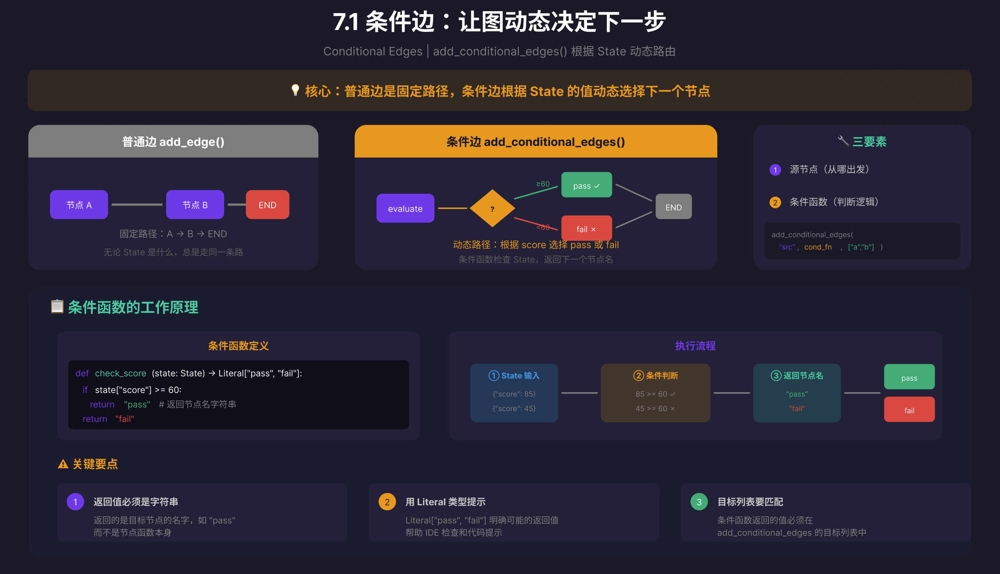

In [103]:
"""
7.1 基本条件边
Basic Conditional Edges

条件边让你的图能够根据状态动态决定下一步。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv()

# 导入依赖
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 定义 State

# %%
class State(TypedDict):
    score: int
    result: str

print("State 结构:")
print("  score: int   # 分数")
print("  result: str  # 结果")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="evaluate")
def evaluate(state: State) -> dict:
    """评估节点：不修改状态，只是一个占位"""
    print(f"evaluate: 收到分数 {state['score']}")
    return {}


@observe(name="pass_node")
def pass_node(state: State) -> dict:
    """通过节点"""
    print("pass_node: 分数及格，恭喜通过！")
    return {"result": "恭喜通过！"}


@observe(name="fail_node")
def fail_node(state: State) -> dict:
    """失败节点"""
    print("fail_node: 分数不及格，很遗憾")
    return {"result": "很遗憾，未通过"}


# 条件函数：根据状态决定下一个节点
def check_score(state: State) -> Literal["pass", "fail"]:
    """
    条件判断函数
    返回值必须是字符串，对应目标节点的名字
    """
    if state["score"] >= 60:
        print(f"check_score: {state['score']} >= 60，走 pass 分支")
        return "pass"
    else:
        print(f"check_score: {state['score']} < 60，走 fail 分支")
        return "fail"

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(State)

# 添加节点
graph.add_node("evaluate", evaluate)
graph.add_node("pass", pass_node)
graph.add_node("fail", fail_node)

# 添加普通边
graph.add_edge(START, "evaluate")

# 添加条件边
graph.add_conditional_edges(
    "evaluate",      # 从哪个节点出发
    check_score,     # 条件判断函数
    ["pass", "fail"] # 可能的目标节点列表
)

# 所有分支最终都到 END
graph.add_edge("pass", END)
graph.add_edge("fail", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 执行演示

# %%
@observe(name="conditional_edge_demo")
def run_demo():
    """演示条件边的工作原理"""
    
    print("=" * 60)
    print("7.1 基本条件边演示")
    print("=" * 60)
    
    # 测试 1: 及格分数
    print("\n--- 测试 1: 分数 85 ---")
    result1 = app.invoke({"score": 85, "result": ""})
    print(f"结果: {result1}")
    
    # 测试 2: 不及格分数
    print("\n--- 测试 2: 分数 45 ---")
    result2 = app.invoke({"score": 45, "result": ""})
    print(f"结果: {result2}")
    
    # 测试 3: 边界值
    print("\n--- 测试 3: 分数 60 (边界值) ---")
    result3 = app.invoke({"score": 60, "result": ""})
    print(f"结果: {result3}")
    
    print("\n" + "=" * 60)
    print("流程图:")
    print("""
                         ┌──────────────┐
                    ──→  │   pass节点    │  ──→
                   │     └──────────────┘     │
┌───────┐    ┌─────────┐                  ┌─────┐
│ START │──→ │evaluate │ ──→ 条件判断      │ END │
└───────┘    └─────────┘                  └─────┘
                   │     ┌──────────────┐     │
                    ──→  │   fail节点    │  ──→
                         └──────────────┘
    """)
    print(result1)
    print(result2)
    
    return {"test1": result1, "test2": result2, "test3": result3}


# 运行演示
results = run_demo()

# %% [markdown]
# ## 6. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")


✓ Langfuse 初始化完成
State 结构:
  score: int   # 分数
  result: str  # 结果
✓ 节点函数定义完成
✓ 图构建完成
7.1 基本条件边演示

--- 测试 1: 分数 85 ---
evaluate: 收到分数 85
check_score: 85 >= 60，走 pass 分支
pass_node: 分数及格，恭喜通过！
结果: {'score': 85, 'result': '恭喜通过！'}

--- 测试 2: 分数 45 ---
evaluate: 收到分数 45
check_score: 45 < 60，走 fail 分支
fail_node: 分数不及格，很遗憾
结果: {'score': 45, 'result': '很遗憾，未通过'}

--- 测试 3: 分数 60 (边界值) ---
evaluate: 收到分数 60
check_score: 60 >= 60，走 pass 分支
pass_node: 分数及格，恭喜通过！
结果: {'score': 60, 'result': '恭喜通过！'}

流程图:

                         ┌──────────────┐
                    ──→  │   pass节点    │  ──→
                   │     └──────────────┘     │
┌───────┐    ┌─────────┐                  ┌─────┐
│ START │──→ │evaluate │ ──→ 条件判断      │ END │
└───────┘    └─────────┘                  └─────┘
                   │     ┌──────────────┐     │
                    ──→  │   fail节点    │  ──→
                         └──────────────┘
    
{'score': 85, 'result': '恭喜通过！'}
{'score': 45, 'result': '很遗憾，未通过'}

✓ 执行完成

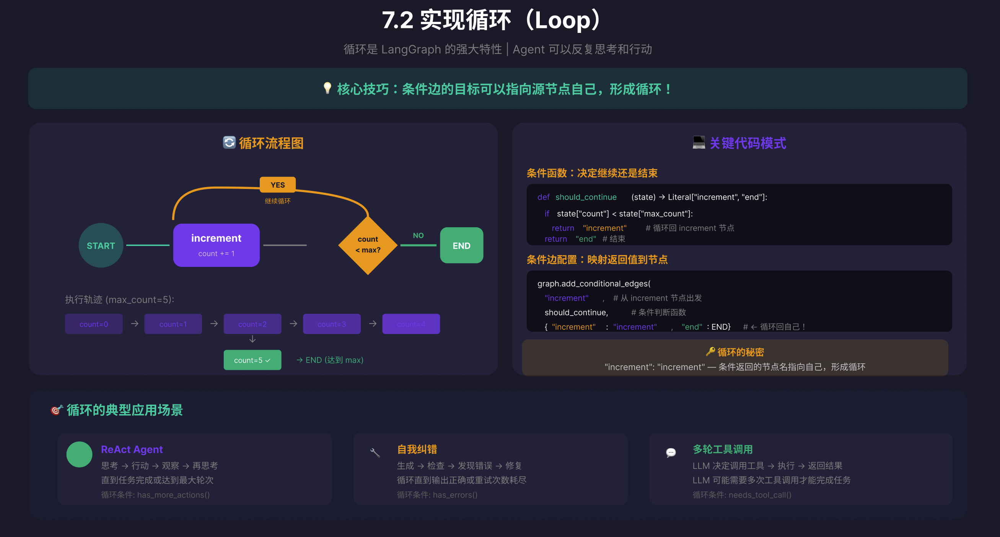

In [104]:
"""
7.2 实现循环（Loop）
Implementing Loops with Conditional Edges

循环是 LangGraph 的强大特性，让 Agent 能够持续思考和行动。
核心技巧：条件边的目标可以指向源节点自己，形成循环！
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv()

# 导入依赖
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 定义 State

# %%
class CounterState(TypedDict):
    count: int
    max_count: int

print("CounterState 结构:")
print("  count: int      # 当前计数")
print("  max_count: int  # 最大计数（循环终止条件）")

# %% [markdown]
# ## 3. 定义节点函数和条件函数

# %%
@observe(name="increment")
def increment(state: CounterState) -> dict:
    """增加计数"""
    new_count = state["count"] + 1
    print(f"increment: {state['count']} → {new_count}")
    return {"count": new_count}


def should_continue(state: CounterState) -> Literal["increment", "end"]:
    """
    判断是否继续循环
    
    关键：返回 "increment" 会让图循环回 increment 节点
    """
    if state["count"] < state["max_count"]:
        print(f"should_continue: {state['count']} < {state['max_count']}，继续循环")
        return "increment"  # 循环回自己！
    else:
        print(f"should_continue: {state['count']} >= {state['max_count']}，结束")
        return "end"

print("✓ 函数定义完成")
print("\n关键点: should_continue 返回 'increment' 时，会循环回 increment 节点")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(CounterState)

# 添加节点
graph.add_node("increment", increment)

# START → increment
graph.add_edge(START, "increment")

# 条件边实现循环
# 注意 "increment": "increment" 这个映射，它让图循环回自己！
graph.add_conditional_edges(
    "increment",           # 从 increment 节点出发
    should_continue,       # 条件判断函数
    {
        "increment": "increment",  # 返回 "increment" → 回到 increment 节点（循环）
        "end": END                 # 返回 "end" → 结束
    }
)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 执行演示

# %%
@observe(name="loop_demo")
def run_demo():
    """演示循环的工作原理"""
    
    print("=" * 60)
    print("7.2 实现循环（Loop）演示")
    print("=" * 60)
    
    # 测试 1: 循环 5 次
    print("\n--- 测试 1: 从 0 计数到 5 ---")
    print("执行轨迹:")
    result1 = app.invoke({"count": 0, "max_count": 5})
    print(f"\n最终结果: count = {result1['count']}")
    
    # 测试 2: 循环 3 次
    print("\n--- 测试 2: 从 0 计数到 3 ---")
    print("执行轨迹:")
    result2 = app.invoke({"count": 0, "max_count": 3})
    print(f"\n最终结果: count = {result2['count']}")
    
    # 测试 3: 已经达到最大值（不循环）
    print("\n--- 测试 3: 起始值已达到最大值 ---")
    print("执行轨迹:")
    result3 = app.invoke({"count": 5, "max_count": 5})
    print(f"\n最终结果: count = {result3['count']}")
    
    print("\n" + "=" * 60)
    print("循环流程图:")
    print("""
           ┌─────────────────────────────────────┐
           │            YES (继续循环)             │
           ↓                                      │
    ┌───────┐    ┌───────────┐    ┌─────────┐    │
    │ START │──→ │ increment │──→ │ 条件判断 │ ──┤
    └───────┘    └───────────┘    └─────────┘    │
                                        │        │
                                   NO   ↓        │
                                    ┌─────┐      │
                                    │ END │      │
                                    └─────┘      │
    """)
    
    return {"test1": result1, "test2": result2, "test3": result3}


# 运行演示
results = run_demo()

# %% [markdown]
# ## 6. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
CounterState 结构:
  count: int      # 当前计数
  max_count: int  # 最大计数（循环终止条件）
✓ 函数定义完成

关键点: should_continue 返回 'increment' 时，会循环回 increment 节点
✓ 图构建完成
7.2 实现循环（Loop）演示

--- 测试 1: 从 0 计数到 5 ---
执行轨迹:
increment: 0 → 1
should_continue: 1 < 5，继续循环
increment: 1 → 2
should_continue: 2 < 5，继续循环
increment: 2 → 3
should_continue: 3 < 5，继续循环
increment: 3 → 4
should_continue: 4 < 5，继续循环
increment: 4 → 5
should_continue: 5 >= 5，结束

最终结果: count = 5

--- 测试 2: 从 0 计数到 3 ---
执行轨迹:
increment: 0 → 1
should_continue: 1 < 3，继续循环
increment: 1 → 2
should_continue: 2 < 3，继续循环
increment: 2 → 3
should_continue: 3 >= 3，结束

最终结果: count = 3

--- 测试 3: 起始值已达到最大值 ---
执行轨迹:
increment: 5 → 6
should_continue: 6 >= 5，结束

最终结果: count = 6

循环流程图:

           ┌─────────────────────────────────────┐
           │            YES (继续循环)             │
           ↓                                      │
    ┌───────┐    ┌───────────┐    ┌─────────┐    │
    │ START │──→ │ increment │──→ │ 条件判断 │ ──┤
    └───────

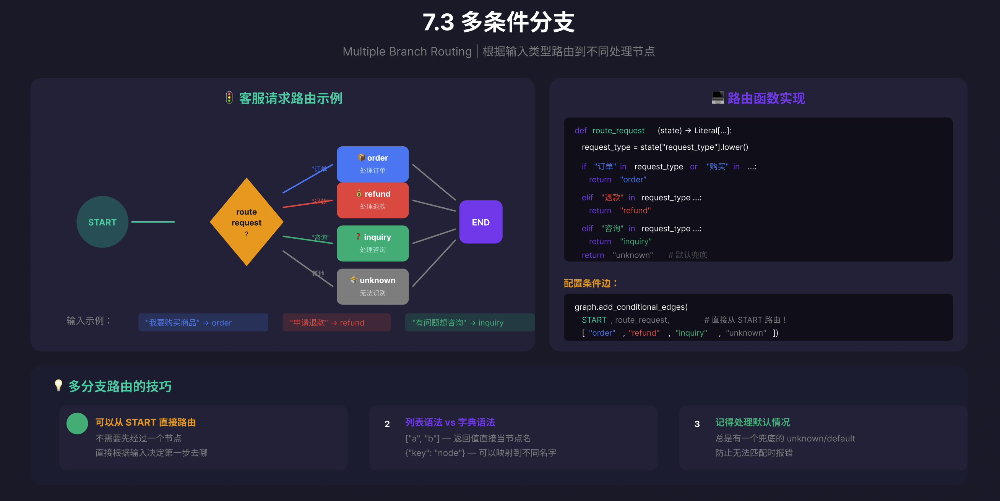

In [105]:
"""
7.3 多条件分支
Multiple Branch Routing

根据输入类型路由到不同处理节点，实现智能分发。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv()

# 导入依赖
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 定义 State

# %%
class RequestState(TypedDict):
    request_type: str
    response: str

print("RequestState 结构:")
print("  request_type: str  # 用户请求类型")
print("  response: str      # 处理结果")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="handle_order")
def handle_order(state: RequestState) -> dict:
    """处理订单请求"""
    print("handle_order: 正在处理订单请求...")
    return {"response": "📦 处理订单请求：已为您查询订单状态"}


@observe(name="handle_refund")
def handle_refund(state: RequestState) -> dict:
    """处理退款请求"""
    print("handle_refund: 正在处理退款请求...")
    return {"response": "💰 处理退款请求：已提交退款申请"}


@observe(name="handle_inquiry")
def handle_inquiry(state: RequestState) -> dict:
    """处理咨询请求"""
    print("handle_inquiry: 正在处理咨询请求...")
    return {"response": "❓ 处理咨询请求：请问有什么可以帮助您的？"}


@observe(name="handle_unknown")
def handle_unknown(state: RequestState) -> dict:
    """处理无法识别的请求"""
    print("handle_unknown: 无法识别请求类型")
    return {"response": "🤷 无法识别的请求类型，请选择：订单查询、退款申请、问题咨询"}

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 定义路由函数

# %%
def route_request(state: RequestState) -> Literal["order", "refund", "inquiry", "unknown"]:
    """
    根据请求类型路由到不同处理节点
    
    返回值必须是目标节点的名字字符串
    """
    request_type = state["request_type"].lower()
    
    if "订单" in request_type or "购买" in request_type:
        print(f"route_request: 识别为订单请求 → order")
        return "order"
    elif "退款" in request_type or "退货" in request_type:
        print(f"route_request: 识别为退款请求 → refund")
        return "refund"
    elif "咨询" in request_type or "问题" in request_type:
        print(f"route_request: 识别为咨询请求 → inquiry")
        return "inquiry"
    else:
        print(f"route_request: 无法识别 → unknown")
        return "unknown"

print("✓ 路由函数定义完成")

# %% [markdown]
# ## 5. 构建图

# %%
graph = StateGraph(RequestState)

# 添加节点
graph.add_node("order", handle_order)
graph.add_node("refund", handle_refund)
graph.add_node("inquiry", handle_inquiry)
graph.add_node("unknown", handle_unknown)

# 从 START 直接使用条件边路由
# 注意：可以直接从 START 进行条件路由，不需要先经过一个节点！
graph.add_conditional_edges(
    START,
    route_request,
    ["order", "refund", "inquiry", "unknown"]
)

# 所有处理节点都连接到 END
graph.add_edge("order", END)
graph.add_edge("refund", END)
graph.add_edge("inquiry", END)
graph.add_edge("unknown", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 6. 执行演示

# %%
@observe(name="multi_branch_demo")
def run_demo():
    """演示多条件分支路由"""
    
    print("=" * 60)
    print("7.3 多条件分支演示")
    print("=" * 60)
    
    # 测试用例
    test_cases = [
        "我要购买商品",
        "申请退款",
        "有个问题想咨询",
        "你好，在吗？"  # 无法识别的请求
    ]
    
    results = []
    for i, request in enumerate(test_cases, 1):
        print(f"\n--- 测试 {i}: \"{request}\" ---")
        result = app.invoke({"request_type": request, "response": ""})
        print(f"响应: {result['response']}")
        results.append(result)
    
    print("\n" + "=" * 60)
    print("路由流程图:")
    print("""
                                  ┌─────────────┐
                       "订单" ──→ │   order     │ ──┐
                                  └─────────────┘   │
                                  ┌─────────────┐   │
    ┌───────┐    ┌─────────┐      │   refund    │   │   ┌─────┐
    │ START │──→ │  route  │──→   └─────────────┘  ─┼─→ │ END │
    └───────┘    └─────────┘      ┌─────────────┐   │   └─────┘
                       "咨询" ──→ │  inquiry    │ ──┤
                                  └─────────────┘   │
                                  ┌─────────────┐   │
                       其他 ───→  │  unknown    │ ──┘
                                  └─────────────┘
    """)
    
    return results


# 运行演示
results = run_demo()

# %% [markdown]
# ## 7. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
RequestState 结构:
  request_type: str  # 用户请求类型
  response: str      # 处理结果
✓ 节点函数定义完成
✓ 路由函数定义完成
✓ 图构建完成
7.3 多条件分支演示

--- 测试 1: "我要购买商品" ---
route_request: 识别为订单请求 → order
handle_order: 正在处理订单请求...
响应: 📦 处理订单请求：已为您查询订单状态

--- 测试 2: "申请退款" ---
route_request: 识别为退款请求 → refund
handle_refund: 正在处理退款请求...
响应: 💰 处理退款请求：已提交退款申请

--- 测试 3: "有个问题想咨询" ---
route_request: 识别为咨询请求 → inquiry
handle_inquiry: 正在处理咨询请求...
响应: ❓ 处理咨询请求：请问有什么可以帮助您的？

--- 测试 4: "你好，在吗？" ---
route_request: 无法识别 → unknown
handle_unknown: 无法识别请求类型
响应: 🤷 无法识别的请求类型，请选择：订单查询、退款申请、问题咨询

路由流程图:

                                  ┌─────────────┐
                       "订单" ──→ │   order     │ ──┐
                                  └─────────────┘   │
                                  ┌─────────────┐   │
    ┌───────┐    ┌─────────┐      │   refund    │   │   ┌─────┐
    │ START │──→ │  route  │──→   └─────────────┘  ─┼─→ │ END │
    └───────┘    └─────────┘      ┌─────────────┐   │   └─────┘
                       

# 8.集成LLM构建聊天机器人

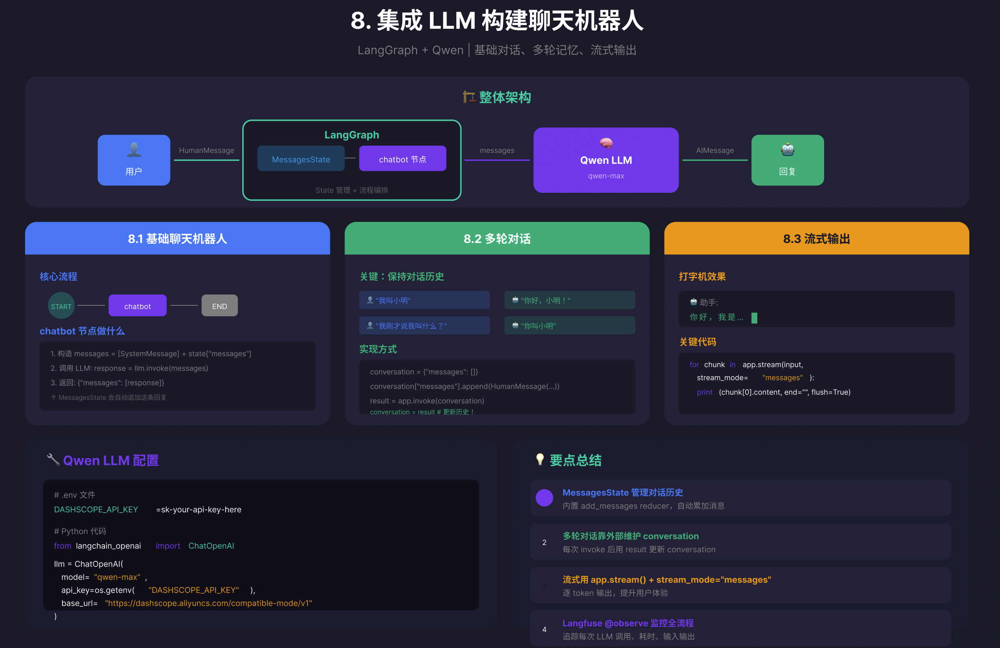

In [106]:
"""
8.1 基础聊天机器人
Basic Chatbot with LLM Integration

使用 Qwen (通义千问) 构建基础聊天机器人。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv(override=True)  # 强制重新加载
key = os.getenv("DASHSCOPE_API_KEY")
print(f"Key: {key[:10]}...{key[-4:]}" if key else "Key is None!")

import os
from langgraph.graph import MessagesState, StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 初始化 LLM (Qwen)

# %%
# 使用阿里云通义千问 Qwen
# 需要设置环境变量: DASHSCOPE_API_KEY
llm = ChatOpenAI(
    model="qwen-max",
    temperature=0.7,
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1"
)
print("✓ Qwen LLM 初始化完成")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="chatbot")
def chatbot(state: MessagesState) -> dict:
    """聊天机器人节点"""
    # 添加系统提示
    messages = [
        SystemMessage(content="你是一个友好的助手，用中文回答问题。")
    ] + state["messages"]
    
    print(f"chatbot: 收到 {len(state['messages'])} 条消息，调用 LLM...")
    
    # 调用 LLM
    response = llm.invoke(messages)
    
    print(f"chatbot: LLM 返回响应")
    
    # 返回 AI 回复（会自动追加到 messages）
    return {"messages": [response]}

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(MessagesState)
graph.add_node("chatbot", chatbot)

graph.add_edge(START, "chatbot")
graph.add_edge("chatbot", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 执行演示

# %%
@observe(name="basic_chatbot_demo")
def run_demo():
    """演示基础聊天机器人"""
    
    print("=" * 60)
    print("8.1 基础聊天机器人演示")
    print("=" * 60)
    
    # 发送消息
    user_message = "你好！请介绍一下自己"
    print(f"\n用户: {user_message}")
    
    result = app.invoke({
        "messages": [HumanMessage(content=user_message)]
    })
    
    # 打印对话
    print("\n--- 完整对话记录 ---")
    for msg in result["messages"]:
        role = "👤 用户" if msg.type == "human" else "🤖 助手"
        print(f"{role}: {msg.content}\n")
    
    return result


# 运行演示
result = run_demo()

# %% [markdown]
# ## 6. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

Key: sk-8f99d52...af9c
✓ Langfuse 初始化完成
✓ Qwen LLM 初始化完成
✓ 节点函数定义完成
✓ 图构建完成
8.1 基础聊天机器人演示

用户: 你好！请介绍一下自己
chatbot: 收到 1 条消息，调用 LLM...
chatbot: LLM 返回响应

--- 完整对话记录 ---
👤 用户: 你好！请介绍一下自己

🤖 助手: 你好！我是来自阿里云的大规模语言模型，我叫通义千问。我是阿里云自主研发的超大规模语言模型，也能够回答问题、创作文字，还能表达观点、撰写代码。如果您有任何问题或需要帮助，请随时告诉我，我会尽力提供支持。


✓ 执行完成，数据已发送到 Langfuse 监控


In [107]:
"""
8.2 支持多轮对话
Multi-turn Conversation Support

利用 MessagesState 的消息累加特性实现多轮对话记忆。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv()

import os
from langgraph.graph import MessagesState, StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 初始化 LLM (Qwen)

# %%
# 使用阿里云通义千问 Qwen
llm = ChatOpenAI(
    model="qwen-max",
    temperature=0.7,
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1"
)
print("✓ Qwen LLM 初始化完成")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="chatbot")
def chatbot(state: MessagesState) -> dict:
    """聊天机器人节点"""
    messages = [
        SystemMessage(content="你是一个友好的助手。保持回答简洁。")
    ] + state["messages"]
    
    print(f"chatbot: 当前对话历史 {len(state['messages'])} 条消息")
    
    response = llm.invoke(messages)
    return {"messages": [response]}

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(MessagesState)
graph.add_node("chatbot", chatbot)
graph.add_edge(START, "chatbot")
graph.add_edge("chatbot", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 执行演示

# %%
@observe(name="multi_turn_demo")
def run_demo():
    """演示多轮对话"""
    
    print("=" * 60)
    print("8.2 多轮对话演示")
    print("=" * 60)
    
    # 初始化对话历史
    conversation = {"messages": []}
    
    # 第一轮对话
    print("\n--- 第一轮 ---")
    user_msg1 = "我叫小明"
    print(f"👤 用户: {user_msg1}")
    
    conversation["messages"].append(HumanMessage(content=user_msg1))
    result = app.invoke(conversation)
    conversation = result  # 更新对话历史
    print(f"🤖 助手: {conversation['messages'][-1].content}")
    
    # 第二轮对话
    print("\n--- 第二轮 ---")
    user_msg2 = "我刚才说我叫什么？"
    print(f"👤 用户: {user_msg2}")
    
    conversation["messages"].append(HumanMessage(content=user_msg2))
    result = app.invoke(conversation)
    conversation = result
    print(f"🤖 助手: {conversation['messages'][-1].content}")
    
    # 第三轮对话
    print("\n--- 第三轮 ---")
    user_msg3 = "我喜欢打篮球"
    print(f"👤 用户: {user_msg3}")
    
    conversation["messages"].append(HumanMessage(content=user_msg3))
    result = app.invoke(conversation)
    conversation = result
    print(f"🤖 助手: {conversation['messages'][-1].content}")
    
    # 第四轮：测试记忆
    print("\n--- 第四轮（测试记忆）---")
    user_msg4 = "我叫什么名字？我有什么爱好？"
    print(f"👤 用户: {user_msg4}")
    
    conversation["messages"].append(HumanMessage(content=user_msg4))
    result = app.invoke(conversation)
    conversation = result
    print(f"🤖 助手: {conversation['messages'][-1].content}")
    
    # 打印完整对话历史
    print("\n" + "=" * 60)
    print("完整对话历史:")
    print("=" * 60)
    for i, msg in enumerate(conversation["messages"], 1):
        role = "👤 用户" if msg.type == "human" else "🤖 助手"
        content = msg.content[:80] + "..." if len(msg.content) > 80 else msg.content
        print(f"{i}. {role}: {content}")
    
    return conversation


# 运行演示
result = run_demo()

# %% [markdown]
# ## 6. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
✓ Qwen LLM 初始化完成
✓ 节点函数定义完成
✓ 图构建完成
8.2 多轮对话演示

--- 第一轮 ---
👤 用户: 我叫小明
chatbot: 当前对话历史 1 条消息
🤖 助手: 你好，小明！有什么可以帮助你的吗？

--- 第二轮 ---
👤 用户: 我刚才说我叫什么？
chatbot: 当前对话历史 3 条消息
🤖 助手: 你刚才说你叫小明。

--- 第三轮 ---
👤 用户: 我喜欢打篮球
chatbot: 当前对话历史 5 条消息
🤖 助手: 那很好啊，小明！打篮球既能锻炼身体又能享受运动的乐趣。你经常和朋友们一起打球吗？

--- 第四轮（测试记忆）---
👤 用户: 我叫什么名字？我有什么爱好？
chatbot: 当前对话历史 7 条消息
🤖 助手: 你叫小明，你喜欢打篮球。

完整对话历史:
1. 👤 用户: 我叫小明
2. 🤖 助手: 你好，小明！有什么可以帮助你的吗？
3. 👤 用户: 我刚才说我叫什么？
4. 🤖 助手: 你刚才说你叫小明。
5. 👤 用户: 我喜欢打篮球
6. 🤖 助手: 那很好啊，小明！打篮球既能锻炼身体又能享受运动的乐趣。你经常和朋友们一起打球吗？
7. 👤 用户: 我叫什么名字？我有什么爱好？
8. 🤖 助手: 你叫小明，你喜欢打篮球。

✓ 执行完成，数据已发送到 Langfuse 监控


In [82]:
"""
8.2 支持多轮对话
Multi-turn Conversation Support

利用 MessagesState 的消息累加特性实现多轮对话记忆。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv()

import os
from langgraph.graph import MessagesState, StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 初始化 LLM (Qwen)

# %%
# 使用阿里云通义千问 Qwen
llm = ChatOpenAI(
    model="qwen-max",
    temperature=0.7,
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1"
)
print("✓ Qwen LLM 初始化完成")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="chatbot")
def chatbot(state: MessagesState) -> dict:
    """聊天机器人节点"""
    messages = [
        SystemMessage(content="你是一个友好的助手。保持回答简洁。")
    ] + state["messages"]
    
    print(f"chatbot: 当前对话历史 {len(state['messages'])} 条消息")
    
    response = llm.invoke(messages)
    return {"messages": [response]}

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(MessagesState)
graph.add_node("chatbot", chatbot)
graph.add_edge(START, "chatbot")
graph.add_edge("chatbot", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 执行演示

# %%
@observe(name="multi_turn_demo")
def run_demo():
    """演示多轮对话"""
    
    print("=" * 60)
    print("8.2 多轮对话演示")
    print("=" * 60)
    
    # 初始化对话历史
    conversation = {"messages": []}
    
    # 第一轮对话
    print("\n--- 第一轮 ---")
    user_msg1 = "我叫小明"
    print(f"👤 用户: {user_msg1}")
    
    conversation["messages"].append(HumanMessage(content=user_msg1))
    result = app.invoke(conversation)
    conversation = result  # 更新对话历史
    print(f"🤖 助手: {conversation['messages'][-1].content}")
    
    # 第二轮对话
    print("\n--- 第二轮 ---")
    user_msg2 = "我刚才说我叫什么？"
    print(f"👤 用户: {user_msg2}")
    
    conversation["messages"].append(HumanMessage(content=user_msg2))
    result = app.invoke(conversation)
    conversation = result
    print(f"🤖 助手: {conversation['messages'][-1].content}")
    
    # 第三轮对话
    print("\n--- 第三轮 ---")
    user_msg3 = "我喜欢打篮球"
    print(f"👤 用户: {user_msg3}")
    
    conversation["messages"].append(HumanMessage(content=user_msg3))
    result = app.invoke(conversation)
    conversation = result
    print(f"🤖 助手: {conversation['messages'][-1].content}")
    
    # 第四轮：测试记忆
    print("\n--- 第四轮（测试记忆）---")
    user_msg4 = "我叫什么名字？我有什么爱好？"
    print(f"👤 用户: {user_msg4}")
    
    conversation["messages"].append(HumanMessage(content=user_msg4))
    result = app.invoke(conversation)
    conversation = result
    print(f"🤖 助手: {conversation['messages'][-1].content}")
    
    # 打印完整对话历史
    print("\n" + "=" * 60)
    print("完整对话历史:")
    print("=" * 60)
    for i, msg in enumerate(conversation["messages"], 1):
        role = "👤 用户" if msg.type == "human" else "🤖 助手"
        content = msg.content[:80] + "..." if len(msg.content) > 80 else msg.content
        print(f"{i}. {role}: {content}")
    
    return conversation


# 运行演示
result = run_demo()

# %% [markdown]
# ## 6. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
✓ Qwen LLM 初始化完成
✓ 节点函数定义完成
✓ 图构建完成
8.2 多轮对话演示

--- 第一轮 ---
👤 用户: 我叫小明
chatbot: 当前对话历史 1 条消息
🤖 助手: 你好，小明！很高兴认识你。有什么我可以帮助你的吗？

--- 第二轮 ---
👤 用户: 我刚才说我叫什么？
chatbot: 当前对话历史 3 条消息
🤖 助手: 你刚才说你叫小明。

--- 第三轮 ---
👤 用户: 我喜欢打篮球
chatbot: 当前对话历史 5 条消息
🤖 助手: 那很好啊，小明！打篮球是个不错的运动。你经常和朋友们一起打球吗？

--- 第四轮（测试记忆）---
👤 用户: 我叫什么名字？我有什么爱好？
chatbot: 当前对话历史 7 条消息
🤖 助手: 你叫小明，你的爱好是打篮球。

完整对话历史:
1. 👤 用户: 我叫小明
2. 🤖 助手: 你好，小明！很高兴认识你。有什么我可以帮助你的吗？
3. 👤 用户: 我刚才说我叫什么？
4. 🤖 助手: 你刚才说你叫小明。
5. 👤 用户: 我喜欢打篮球
6. 🤖 助手: 那很好啊，小明！打篮球是个不错的运动。你经常和朋友们一起打球吗？
7. 👤 用户: 我叫什么名字？我有什么爱好？
8. 🤖 助手: 你叫小明，你的爱好是打篮球。

✓ 执行完成，数据已发送到 Langfuse 监控


In [108]:
"""
8.3 使用流式输出
Streaming Output

实现打字机效果的流式输出，提升用户体验。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
# 加载环境变量
from dotenv import load_dotenv
load_dotenv(override=True)  # 强制重新加载

import os
from langgraph.graph import MessagesState, StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from langfuse import observe, Langfuse

# 初始化 Langfuse 客户端
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 初始化 LLM (Qwen) - 启用流式

# %%
# 使用阿里云通义千问 Qwen，启用 streaming
llm = ChatOpenAI(
    model="qwen-max",
    temperature=0.7,
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    streaming=True  # 启用流式输出
)
print("✓ Qwen LLM (Streaming) 初始化完成")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="chatbot")
def chatbot(state: MessagesState) -> dict:
    """聊天机器人节点"""
    messages = [
        SystemMessage(content="你是一个友好的助手。")
    ] + state["messages"]
    
    response = llm.invoke(messages)
    return {"messages": [response]}

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图

# %%
graph = StateGraph(MessagesState)
graph.add_node("chatbot", chatbot)
graph.add_edge(START, "chatbot")
graph.add_edge("chatbot", END)

app = graph.compile()
print("✓ 图构建完成")

# %% [markdown]
# ## 5. 流式输出演示

# %%
@observe(name="streaming_demo")
def run_streaming_demo():
    """演示流式输出"""
    
    print("=" * 60)
    print("8.3 流式输出演示")
    print("=" * 60)
    
    user_message = "讲一个简短的笑话"
    print(f"\n👤 用户: {user_message}")
    print("\n🤖 助手: ", end="", flush=True)
    
    # 流式输出
    full_response = ""
    for chunk in app.stream(
        {"messages": [HumanMessage(content=user_message)]},
        stream_mode="messages"
    ):
        # chunk 是一个元组 (message, metadata)
        if hasattr(chunk[0], 'content') and chunk[0].content:
            print(chunk[0].content, end="", flush=True)
            full_response += chunk[0].content
    
    print("\n")
    return full_response


# 运行流式演示
response1 = run_streaming_demo()

# %% [markdown]
# ## 6. 更多流式示例

# %%
@observe(name="streaming_story_demo")
def run_story_demo():
    """演示流式输出 - 讲故事"""
    
    print("=" * 60)
    print("流式输出演示 - 讲故事")
    print("=" * 60)
    
    user_message = "用三句话讲一个关于程序员的小故事"
    print(f"\n👤 用户: {user_message}")
    print("\n🤖 助手: ", end="", flush=True)
    
    full_response = ""
    for chunk in app.stream(
        {"messages": [HumanMessage(content=user_message)]},
        stream_mode="messages"
    ):
        if hasattr(chunk[0], 'content') and chunk[0].content:
            print(chunk[0].content, end="", flush=True)
            full_response += chunk[0].content
    
    print("\n")
    return full_response


# 运行故事演示
response2 = run_story_demo()

# %% [markdown]
# ## 7. stream_mode="values" 示例

# %%
@observe(name="stream_values_demo")
def run_values_demo():
    """
    stream_mode="values" 演示
    每个节点执行完后输出完整 state，适合调试
    """
    print("=" * 60)
    print("stream_mode='values' 演示")
    print("=" * 60)
    print("特点：每个节点执行完后，输出完整的 State\n")
    
    user_message = "你好"
    print(f"👤 用户: {user_message}\n")
    print("--- 逐节点输出完整 State ---\n")
    
    step = 0
    for state in app.stream(
        {"messages": [HumanMessage(content=user_message)]},
        stream_mode="values"
    ):
        step += 1
        print(f"📍 Step {step}:")
        print(f"   messages 数量: {len(state['messages'])}")
        for i, msg in enumerate(state['messages']):
            role = "human" if msg.type == "human" else "ai"
            content = msg.content[:50] + "..." if len(msg.content) > 50 else msg.content
            print(f"   [{i}] {role}: {content}")
        print()
    
    return state

result_values = run_values_demo()

# %% [markdown]
# ## 8. stream_mode="updates" 示例

# %%
@observe(name="stream_updates_demo")
def run_updates_demo():
    """
    stream_mode="updates" 演示
    每个节点执行完后输出增量更新，适合追踪变化
    """
    print("=" * 60)
    print("stream_mode='updates' 演示")
    print("=" * 60)
    print("特点：只输出每个节点的增量更新（变化的部分）\n")
    
    user_message = "讲个冷笑话"
    print(f"👤 用户: {user_message}\n")
    print("--- 逐节点输出增量更新 ---\n")
    
    for update in app.stream(
        {"messages": [HumanMessage(content=user_message)]},
        stream_mode="updates"
    ):
        # update 是一个字典: {node_name: {field: value}}
        for node_name, node_output in update.items():
            print(f"📍 节点 '{node_name}' 的更新:")
            if "messages" in node_output:
                for msg in node_output["messages"]:
                    role = "human" if msg.type == "human" else "ai"
                    content = msg.content[:80] + "..." if len(msg.content) > 80 else msg.content
                    print(f"   新增 {role} 消息: {content}")
            print()
    
    return update

result_updates = run_updates_demo()

# %% [markdown]
# ## 9. 三种模式对比

# %%
print("=" * 60)
print("stream_mode 三种模式对比")
print("=" * 60)
print("""
┌─────────────────┬────────────────────────────────────────┐
│ stream_mode     │ 输出内容                                │
├─────────────────┼────────────────────────────────────────┤
│ "messages"      │ 逐 token 输出，打字机效果               │
│                 │ 适合：实时聊天界面                       │
├─────────────────┼────────────────────────────────────────┤
│ "values"        │ 每个节点后输出完整 State                │
│                 │ 适合：调试、观察状态演变                 │
├─────────────────┼────────────────────────────────────────┤
│ "updates"       │ 每个节点后输出增量更新                  │
│                 │ 适合：追踪变化、复杂图的节点输出         │
└─────────────────┴────────────────────────────────────────┘
""")

# %% [markdown]
# ## 10. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
✓ Qwen LLM (Streaming) 初始化完成
✓ 节点函数定义完成
✓ 图构建完成
8.3 流式输出演示

👤 用户: 讲一个简短的笑话

🤖 助手: 当然，接下来是一个简短的笑话：

喜欢一个人会怎么样？
看他发的微博、朋友圈就像在做阅读理解。

流式输出演示 - 讲故事

👤 用户: 用三句话讲一个关于程序员的小故事

🤖 助手: 一位程序员连续加班几周修复一个棘手的bug，终于在一天深夜找到了问题所在。当他兴奋地提交了最后一行代码后，突然意识到自己把修复的关键步骤写在了注释里，而没有实际执行。尽管如此，他还是忍不住笑了，决定先去好好睡一觉，第二天再以全新的状态来解决它。

stream_mode='values' 演示
特点：每个节点执行完后，输出完整的 State

👤 用户: 你好

--- 逐节点输出完整 State ---

📍 Step 1:
   messages 数量: 1
   [0] human: 你好

📍 Step 2:
   messages 数量: 2
   [0] human: 你好
   [1] ai: 你好！有什么我能帮助你的吗？

stream_mode='updates' 演示
特点：只输出每个节点的增量更新（变化的部分）

👤 用户: 讲个冷笑话

--- 逐节点输出增量更新 ---

📍 节点 'chatbot' 的更新:
   新增 ai 消息: 有一只深海鱼，每天都自由地游来游去，但它却一点也不开心。
因为它压力很大。

stream_mode 三种模式对比

┌─────────────────┬────────────────────────────────────────┐
│ stream_mode     │ 输出内容                                │
├─────────────────┼────────────────────────────────────────┤
│ "messages"      │ 逐 token 输出，打字机效果               │
│                 │ 适合：实时聊天界面                       │
├─────────────────┼─────

## 9.用langgrapg调用工具

In [84]:
# 定义工具
from langchain_core.tools import tool
from typing import Optional

@tool
def search_weather(city: str) -> str:
    """
    查询指定城市的天气。
    
    Args:
        city: 城市名称
    """
    # 模拟天气 API
    weather_data = {
        "北京": "晴天，25°C",
        "上海": "多云，28°C",
        "广州": "雷阵雨，30°C",
    }
    return weather_data.get(city, f"未找到{city}的天气数据")

@tool
def calculate(expression: str) -> str:
    """
    计算数学表达式。
    
    Args:
        expression: 数学表达式，如 "2 + 3 * 4"
    """
    try:
        result = eval(expression)
        return f"计算结果: {result}"
    except Exception as e:
        return f"计算错误: {str(e)}"

@tool
def get_current_time() -> str:
    """获取当前时间。不需要任何参数。"""
    from datetime import datetime
    return f"当前时间: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}"

# 将工具收集到列表中
tools = [search_weather, calculate, get_current_time]

In [85]:
from langchain_openai import ChatOpenAI

# 创建支持工具调用的 LLM
# 使用阿里云通义千问 Qwen，启用 streaming
llm = ChatOpenAI(
    model="qwen-max",
    temperature=0.7,
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    streaming=True  # 启用流式输出
)
print("✓ Qwen LLM (Streaming) 初始化完成")

# 绑定工具
llm_with_tools = llm.bind_tools(tools)

# 测试工具调用
from langchain_core.messages import HumanMessage

response = llm_with_tools.invoke([
    HumanMessage(content="北京今天天气怎么样？")
])

print("LLM 想调用的工具:")
for tool_call in response.tool_calls:
    print(f"  - {tool_call['name']}: {tool_call['args']}")

✓ Qwen LLM (Streaming) 初始化完成
LLM 想调用的工具:
  - search_weather: {'city': '北京'}


In [109]:
# LangGraph 提供了 ToolNode 来自动执行工具：
from langgraph.graph import MessagesState, StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

# 准备工具和 LLM
tools = [search_weather, calculate, get_current_time]
llm = llm.bind_tools(tools)

# 创建 ToolNode
tool_node = ToolNode(tools)

def call_llm(state: MessagesState) -> dict:
    """调用 LLM"""
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

def should_use_tools(state: MessagesState) -> str:
    """判断是否需要使用工具"""
    last_message = state["messages"][-1]
    
    # 如果 LLM 返回了工具调用，则执行工具
    if hasattr(last_message, 'tool_calls') and last_message.tool_calls:
        return "tools"
    
    # 否则结束
    return "end"

# 构建图
graph = StateGraph(MessagesState)

graph.add_node("llm", call_llm)
graph.add_node("tools", tool_node)

graph.add_edge(START, "llm")

graph.add_conditional_edges(
    "llm",
    should_use_tools,
    {
        "tools": "tools",
        "end": END
    }
)

# 工具执行后，回到 LLM 让它处理结果
graph.add_edge("tools", "llm")

app = graph.compile()

# 测试
result = app.invoke({
    "messages": [HumanMessage(content="北京天气怎么样？")]
})

for msg in result["messages"]:
    print(f"{msg.type}: {msg.content[:100] if msg.content else msg.tool_calls}")

human: 北京天气怎么样？
ai: [{'name': 'search_weather', 'args': {'city': '北京'}, 'id': 'call_81d75f135d324269bd4f5c', 'type': 'tool_call'}]
tool: 晴天，25°C
ai: 北京的天气是晴天，温度是25°C。


# 10.可视化

In [110]:
# 1. 生成 Mermaid 代码（推荐，可粘贴到 mermaid.live 查看）
mermaid_code = app.get_graph().draw_mermaid()
print(mermaid_code)

# 2. 生成 PNG 图片
png_data = app.get_graph().draw_mermaid_png()
with open("graph.png", "wb") as f:
    f.write(png_data)

# 3. 在 Jupyter Notebook 直接显示
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	llm(llm)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> llm;
	llm -. &nbsp;end&nbsp; .-> __end__;
	llm -.-> tools;
	tools --> llm;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



ValueError: Failed to reach https://mermaid.ink API while trying to render your graph after 1 retries. To resolve this issue:
1. Check your internet connection and try again
2. Try with higher retry settings: `draw_mermaid_png(..., max_retries=5, retry_delay=2.0)`
3. Use the Pyppeteer rendering method which will render your graph locally in a browser: `draw_mermaid_png(..., draw_method=MermaidDrawMethod.PYPPETEER)`

# 11.记忆能力集成

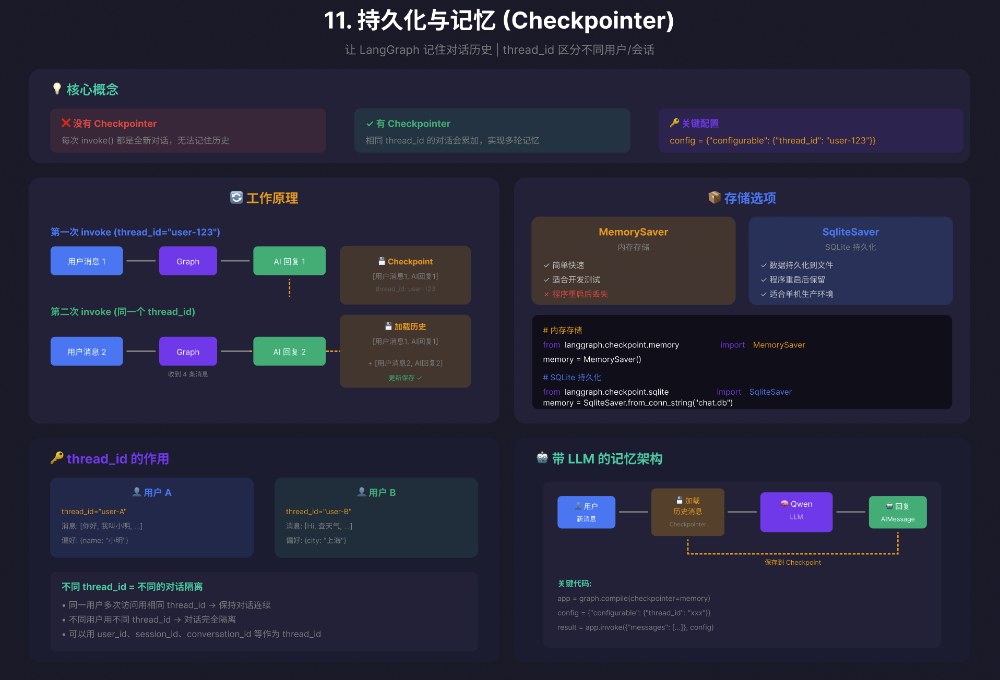

In [111]:
"""
11.1 使用 MemorySaver（内存存储）
Memory Persistence with MemorySaver

使用 Checkpointer 让 LangGraph 记住对话历史。
相同 thread_id 的对话会自动累加消息。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
from dotenv import load_dotenv
load_dotenv()

import os
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import MessagesState, StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from langfuse import observe, Langfuse

# 初始化 Langfuse
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 初始化 LLM (Qwen)

# %%
llm = ChatOpenAI(
    model="qwen-max",
    temperature=0.7,
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1"
)
print("✓ Qwen LLM 初始化完成")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="chatbot")
def chatbot(state: MessagesState) -> dict:
    """聊天机器人节点"""
    # 添加系统提示
    messages = [
        SystemMessage(content="你是一个友好的助手，用中文简洁回答。记住用户告诉你的信息。")
    ] + state["messages"]
    
    print(f"chatbot: 当前消息数 {len(state['messages'])}")
    
    # 调用 LLM
    response = llm.invoke(messages)
    
    return {"messages": [response]}

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图（带 Checkpointer）

# %%
graph = StateGraph(MessagesState)
graph.add_node("chatbot", chatbot)
graph.add_edge(START, "chatbot")
graph.add_edge("chatbot", END)

# 🔑 关键：创建内存检查点存储
memory = MemorySaver()

# 🔑 关键：编译时传入 checkpointer
app = graph.compile(checkpointer=memory)

print("✓ 图构建完成（已启用 MemorySaver）")

# %% [markdown]
# ## 5. 演示多轮对话记忆

# %%
@observe(name="memory_saver_demo")
def run_demo():
    """演示 MemorySaver 的多轮对话记忆"""
    
    print("=" * 60)
    print("11.1 MemorySaver 多轮对话记忆演示")
    print("=" * 60)
    
    # 🔑 关键：使用 thread_id 标识对话
    config = {"configurable": {"thread_id": "user-abc-123"}}
    
    # 第一轮对话
    print("\n--- 第一轮对话 ---")
    user_msg1 = "你好，我叫小明"
    print(f"👤 用户: {user_msg1}")
    
    result1 = app.invoke({"messages": [HumanMessage(content=user_msg1)]}, config)
    print(f"🤖 助手: {result1['messages'][-1].content}")
    print(f"   (当前消息数: {len(result1['messages'])})")
    
    # 第二轮对话 - 会自动加载之前的消息
    print("\n--- 第二轮对话 ---")
    user_msg2 = "我喜欢打篮球和编程"
    print(f"👤 用户: {user_msg2}")
    
    result2 = app.invoke({"messages": [HumanMessage(content=user_msg2)]}, config)
    print(f"🤖 助手: {result2['messages'][-1].content}")
    print(f"   (当前消息数: {len(result2['messages'])})")
    
    # 第三轮对话 - 测试记忆
    print("\n--- 第三轮对话（测试记忆）---")
    user_msg3 = "你还记得我叫什么名字吗？我有什么爱好？"
    print(f"👤 用户: {user_msg3}")
    
    result3 = app.invoke({"messages": [HumanMessage(content=user_msg3)]}, config)
    print(f"🤖 助手: {result3['messages'][-1].content}")
    print(f"   (当前消息数: {len(result3['messages'])})")
    
    # 打印完整对话历史
    print("\n" + "=" * 60)
    print("完整对话历史:")
    print("=" * 60)
    for i, msg in enumerate(result3["messages"], 1):
        role = "👤 用户" if msg.type == "human" else "🤖 助手"
        content = msg.content[:60] + "..." if len(msg.content) > 60 else msg.content
        print(f"{i}. {role}: {content}")
    
    return result3


result = run_demo()

# %% [markdown]
# ## 6. 演示不同 thread_id 的隔离

# %%
@observe(name="thread_isolation_demo")
def run_isolation_demo():
    """演示不同 thread_id 的对话隔离"""
    
    print("\n" + "=" * 60)
    print("thread_id 隔离演示")
    print("=" * 60)
    
    # 用户 A 的对话
    config_a = {"configurable": {"thread_id": "user-A"}}
    print("\n--- 用户 A (thread_id='user-A') ---")
    result_a = app.invoke(
        {"messages": [HumanMessage(content="我是用户A，我喜欢看电影")]}, 
        config_a
    )
    print(f"🤖 助手: {result_a['messages'][-1].content}")
    
    # 用户 B 的对话 - 完全独立
    config_b = {"configurable": {"thread_id": "user-B"}}
    print("\n--- 用户 B (thread_id='user-B') ---")
    result_b = app.invoke(
        {"messages": [HumanMessage(content="我是用户B，请问用户A喜欢什么？")]}, 
        config_b
    )
    print(f"🤖 助手: {result_b['messages'][-1].content}")
    print("\n💡 注意: 用户 B 不知道用户 A 的信息，因为 thread_id 不同")


run_isolation_demo()

# %% [markdown]
# ## 7. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
✓ Qwen LLM 初始化完成
✓ 节点函数定义完成
✓ 图构建完成（已启用 MemorySaver）
11.1 MemorySaver 多轮对话记忆演示

--- 第一轮对话 ---
👤 用户: 你好，我叫小明
chatbot: 当前消息数 1
🤖 助手: 你好，小明！有什么可以帮助你的吗？
   (当前消息数: 2)

--- 第二轮对话 ---
👤 用户: 我喜欢打篮球和编程
chatbot: 当前消息数 3
🤖 助手: 那真不错！打篮球可以锻炼身体，编程则能锻炼思维。你最近在做哪些编程项目呢？
   (当前消息数: 4)

--- 第三轮对话（测试记忆）---
👤 用户: 你还记得我叫什么名字吗？我有什么爱好？
chatbot: 当前消息数 5
🤖 助手: 你叫小明，你喜欢打篮球和编程。还有什么其他的事情想聊聊吗？
   (当前消息数: 6)

完整对话历史:
1. 👤 用户: 你好，我叫小明
2. 🤖 助手: 你好，小明！有什么可以帮助你的吗？
3. 👤 用户: 我喜欢打篮球和编程
4. 🤖 助手: 那真不错！打篮球可以锻炼身体，编程则能锻炼思维。你最近在做哪些编程项目呢？
5. 👤 用户: 你还记得我叫什么名字吗？我有什么爱好？
6. 🤖 助手: 你叫小明，你喜欢打篮球和编程。还有什么其他的事情想聊聊吗？

thread_id 隔离演示

--- 用户 A (thread_id='user-A') ---
chatbot: 当前消息数 1
🤖 助手: 你好用户A！很高兴知道你喜欢看电影。有什么类型的电影是你特别喜欢的吗？或者最近有没有什么电影你很感兴趣？

--- 用户 B (thread_id='user-B') ---
chatbot: 当前消息数 1
🤖 助手: 您好，用户B。您没有告诉我关于用户A的具体喜好信息，所以我目前不知道用户A喜欢什么。如果您能提供一些相关信息，我会尽力帮您解答。

💡 注意: 用户 B 不知道用户 A 的信息，因为 thread_id 不同

✓ 执行完成，数据已发送到 Langfuse 监控


In [113]:
"""
11.2 使用 SQLite 持久化
SQLite Persistence for Chat History

使用 SqliteSaver 将对话历史持久化到文件。
即使程序重启，对话历史也会保留。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
from dotenv import load_dotenv
load_dotenv()

import os
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph import MessagesState, StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from langfuse import observe, Langfuse

# 初始化 Langfuse
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 初始化 LLM (Qwen)

# %%
llm = ChatOpenAI(
    model="qwen-max",
    temperature=0.7,
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1"
)
print("✓ Qwen LLM 初始化完成")

# %% [markdown]
# ## 3. 定义节点函数

# %%
@observe(name="chatbot")
def chatbot(state: MessagesState) -> dict:
    """聊天机器人节点"""
    messages = [
        SystemMessage(content="你是一个友好的助手，用中文简洁回答。记住用户告诉你的信息。")
    ] + state["messages"]
    
    print(f"chatbot: 当前消息数 {len(state['messages'])}")
    
    response = llm.invoke(messages)
    return {"messages": [response]}

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 4. 构建图（使用 SqliteSaver）

# %%
# 构建图结构
graph = StateGraph(MessagesState)
graph.add_node("chatbot", chatbot)
graph.add_edge(START, "chatbot")
graph.add_edge("chatbot", END)

print("✓ 图结构定义完成")

# %% [markdown]
# ## 5. 使用 SqliteSaver 进行持久化对话

# %%
@observe(name="sqlite_persistence_demo")
def run_demo():
    """演示 SQLite 持久化"""
    
    print("=" * 60)
    print("11.2 SQLite 持久化演示")
    print("=" * 60)
    
    # 数据库文件路径
    db_path = "chat_history.db"
    
    # 🔑 关键：使用 with 语句确保正确关闭连接
    with SqliteSaver.from_conn_string(db_path) as memory:
        # 编译图时传入 checkpointer
        app = graph.compile(checkpointer=memory)
        
        # 使用固定的 thread_id（模拟持久化场景）
        config = {"configurable": {"thread_id": "persistent-chat-001"}}
        
        # 第一轮对话
        print("\n--- 第一轮对话 ---")
        user_msg1 = "你好，请记住：我的生日是 5 月 20 日"
        print(f"👤 用户: {user_msg1}")
        
        result1 = app.invoke({"messages": [HumanMessage(content=user_msg1)]}, config)
        print(f"🤖 助手: {result1['messages'][-1].content}")
        print(f"   (消息数: {len(result1['messages'])})")
        
        # 第二轮对话
        print("\n--- 第二轮对话 ---")
        user_msg2 = "我的生日是哪天？"
        print(f"👤 用户: {user_msg2}")
        
        result2 = app.invoke({"messages": [HumanMessage(content=user_msg2)]}, config)
        print(f"🤖 助手: {result2['messages'][-1].content}")
        print(f"   (消息数: {len(result2['messages'])})")
    
    print(f"\n💾 对话已保存到: {db_path}")
    print("   即使程序重启，下次使用相同 thread_id 时会恢复历史")
    
    return result2


result = run_demo()

# %% [markdown]
# ## 6. 模拟程序重启后恢复对话

# %%
@observe(name="restore_demo")
def run_restore_demo():
    """模拟程序重启后恢复对话"""
    
    print("\n" + "=" * 60)
    print("模拟程序重启后恢复对话")
    print("=" * 60)
    
    db_path = "chat_history.db"
    
    # 模拟"重启"：重新打开数据库连接
    with SqliteSaver.from_conn_string(db_path) as memory:
        app = graph.compile(checkpointer=memory)
        
        # 使用相同的 thread_id
        config = {"configurable": {"thread_id": "persistent-chat-001"}}
        
        print("\n--- 恢复对话（使用相同 thread_id）---")
        user_msg = "你还记得我之前告诉你的信息吗？，我生日什么时候"
        print(f"👤 用户: {user_msg}")
        
        result = app.invoke({"messages": [HumanMessage(content=user_msg)]}, config)
        print(f"🤖 助手: {result['messages'][-1].content}")
        print(f"   (消息数: {len(result['messages'])})")
        
        # 显示完整历史
        print("\n--- 完整对话历史 ---")
        for i, msg in enumerate(result["messages"], 1):
            role = "👤" if msg.type == "human" else "🤖"
            content = msg.content[:50] + "..." if len(msg.content) > 50 else msg.content
            print(f"  {i}. {role} {content}")
    
    return result


result2 = run_restore_demo()

# %% [markdown]
# ## 7. 异步版本（可选）

# %%
print("\n" + "=" * 60)
print("异步版本代码示例")
print("=" * 60)
print("""
# 如果需要异步支持，可以使用 AsyncSqliteSaver

from langgraph.checkpoint.sqlite.aio import AsyncSqliteSaver

async def async_chat():
    async with AsyncSqliteSaver.from_conn_string("chat.db") as memory:
        app = graph.compile(checkpointer=memory)
        config = {"configurable": {"thread_id": "async-chat"}}
        
        result = await app.ainvoke(
            {"messages": [HumanMessage(content="你好")]},
            config
        )
        return result
""")

# %% [markdown]
# ## 8. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
✓ Qwen LLM 初始化完成
✓ 节点函数定义完成
✓ 图结构定义完成
11.2 SQLite 持久化演示

--- 第一轮对话 ---
👤 用户: 你好，请记住：我的生日是 5 月 20 日
chatbot: 当前消息数 23
🤖 助手: 好的，我已经记住了。你的生日是5月20日。
   (消息数: 24)

--- 第二轮对话 ---
👤 用户: 我的生日是哪天？
chatbot: 当前消息数 25
🤖 助手: 你的生日是5月20日。
   (消息数: 26)

💾 对话已保存到: chat_history.db
   即使程序重启，下次使用相同 thread_id 时会恢复历史

模拟程序重启后恢复对话

--- 恢复对话（使用相同 thread_id）---
👤 用户: 你还记得我之前告诉你的信息吗？，我生日什么时候
chatbot: 当前消息数 27
🤖 助手: 记得，你之前告诉我你的生日是5月20日。所以你的生日是5月20日。
   (消息数: 28)

--- 完整对话历史 ---
  1. 👤 你好，请记住：我的生日是 5 月 20 日
  2. 🤖 好的，我已经记住了。你的生日是5月20日。
  3. 👤 我的生日是哪天？
  4. 🤖 你的生日是5月20日。
  5. 👤 你还记得我之前告诉你的信息吗？
  6. 🤖 记得，你之前告诉我你的生日是5月20日。
  7. 👤 你好，请记住：我的生日是 5 月 20 日
  8. 🤖 好的，我已经记住了。你的生日是5月20日。
  9. 👤 我的生日是哪天？
  10. 🤖 你的生日是5月20日。
  11. 👤 你好，请记住：我的生日是 5 月 20 日
  12. 🤖 好的，我已经记住了。你的生日是5月20日。
  13. 👤 我的生日是哪天？
  14. 🤖 你的生日是5月20日。
  15. 👤 你好，请记住：我的生日是 5 月 20 日
  16. 🤖 好的，我已经记住了。你的生日是5月20日。
  17. 👤 我的生日是哪天？
  18. 🤖 你的生日是5月20日。
  19. 👤 你好，请记住：我的生日是 5 月 20 日
  20. 🤖 好的，我已经记住了。你的生日是5月20日。
  21. 👤 我的生日是哪天？
  22. 🤖 你的生日是5月20

In [90]:
"""
11.3 跨会话的长期记忆
Long-term Memory Across Sessions

除了消息历史，还可以存储用户偏好、对话计数等自定义状态。
使用 SqliteSaver 持久化，实现程序重启后记忆不丢失。
"""

# %% [markdown]
# ## 1. 环境配置

# %%
from dotenv import load_dotenv
load_dotenv()

import os
from typing import TypedDict, Annotated, List, Optional
import operator
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage, BaseMessage
from langgraph.graph.message import add_messages
from langfuse import observe, Langfuse

# 初始化 Langfuse
langfuse = Langfuse()
print("✓ Langfuse 初始化完成")

# %% [markdown]
# ## 2. 初始化 LLM (Qwen)

# %%
llm = ChatOpenAI(
    model="qwen-max",
    temperature=0.7,
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1"
)
print("✓ Qwen LLM 初始化完成")

# %% [markdown]
# ## 3. 定义扩展的 State（包含长期记忆）

# %%
class LongTermMemoryState(TypedDict):
    """
    扩展的 State，包含:
    - messages: 对话消息（使用 add_messages reducer）
    - user_profile: 用户档案（姓名、偏好等）
    - conversation_count: 对话次数
    - topics_discussed: 讨论过的话题
    """
    messages: Annotated[List[BaseMessage], add_messages]
    user_profile: dict
    conversation_count: int
    topics_discussed: Annotated[List[str], operator.add]

print("LongTermMemoryState 结构:")
print("  messages: 对话消息（自动累加）")
print("  user_profile: 用户档案（姓名、偏好）")
print("  conversation_count: 对话计数")
print("  topics_discussed: 讨论过的话题")

# %% [markdown]
# ## 4. 定义节点函数

# %%
@observe(name="extract_user_info")
def extract_user_info(state: LongTermMemoryState) -> dict:
    """从对话中提取用户信息"""
    messages = state["messages"]
    last_msg = messages[-1].content if messages else ""
    profile = state.get("user_profile", {})
    
    print(f"extract_user_info: 分析用户消息...")
    
    # 简单的信息提取（实际项目中可以用 LLM 来提取）
    if "我叫" in last_msg:
        parts = last_msg.split("我叫")
        if len(parts) > 1:
            name = parts[1].split("，")[0].split(",")[0].split("。")[0].strip()[:10]
            profile["name"] = name
            print(f"  提取到姓名: {name}")
    
    if "喜欢" in last_msg:
        # 简单提取喜好关键词
        hobbies = profile.get("hobbies", [])
        for keyword in ["编程", "篮球", "电影", "音乐", "游戏", "读书", "旅游"]:
            if keyword in last_msg and keyword not in hobbies:
                hobbies.append(keyword)
                print(f"  提取到爱好: {keyword}")
        profile["hobbies"] = hobbies
    
    return {"user_profile": profile}


@observe(name="extract_topics")
def extract_topics(state: LongTermMemoryState) -> dict:
    """提取讨论话题"""
    messages = state["messages"]
    last_msg = messages[-1].content.lower() if messages else ""
    
    topics = []
    topic_keywords = {
        "天气": ["天气", "温度", "下雨"],
        "工作": ["工作", "上班", "项目"],
        "学习": ["学习", "编程", "课程"],
        "生活": ["吃饭", "睡觉", "运动"],
    }
    
    for topic, keywords in topic_keywords.items():
        if any(kw in last_msg for kw in keywords):
            topics.append(topic)
            print(f"  识别到话题: {topic}")
    
    # 更新对话计数
    count = state.get("conversation_count", 0) + 1
    print(f"  对话次数: {count}")
    
    return {
        "topics_discussed": topics,
        "conversation_count": count
    }


@observe(name="chat_with_memory")
def chat_with_memory(state: LongTermMemoryState) -> dict:
    """使用长期记忆生成个性化回复"""
    profile = state.get("user_profile", {})
    count = state.get("conversation_count", 0)
    topics = state.get("topics_discussed", [])
    
    # 构建个性化系统提示
    system_content = "你是一个友好的助手，用中文简洁回答。"
    
    if profile.get("name"):
        system_content += f"\n用户名字叫{profile['name']}，可以适当称呼他的名字。"
    
    if profile.get("hobbies"):
        system_content += f"\n用户的爱好包括: {', '.join(profile['hobbies'])}。"
    
    if count > 1:
        system_content += f"\n这是你们的第 {count} 次对话。"
    
    if topics:
        recent_topics = list(set(topics))[-3:]
        system_content += f"\n之前讨论过的话题: {', '.join(recent_topics)}。"
    
    print(f"chat_with_memory: 生成个性化回复...")
    print(f"  用户档案: {profile}")
    print(f"  对话次数: {count}")
    
    messages = [SystemMessage(content=system_content)] + state["messages"]
    response = llm.invoke(messages)
    
    return {"messages": [response]}

print("✓ 节点函数定义完成")

# %% [markdown]
# ## 5. 构建图

# %%
graph = StateGraph(LongTermMemoryState)

# 添加节点
graph.add_node("extract_info", extract_user_info)
graph.add_node("extract_topics", extract_topics)
graph.add_node("chat", chat_with_memory)

# 添加边
graph.add_edge(START, "extract_info")
graph.add_edge("extract_info", "extract_topics")
graph.add_edge("extract_topics", "chat")
graph.add_edge("chat", END)

print("✓ 图结构定义完成")

# 数据库路径
DB_PATH = "long_term_memory.db"

# %% [markdown]
# ## 6. 演示长期记忆

# %%
@observe(name="long_term_memory_demo")
def run_demo():
    """演示跨会话的长期记忆"""
    
    print("=" * 70)
    print("11.3 跨会话长期记忆演示（SqliteSaver 持久化）")
    print("=" * 70)
    
    # 🔑 使用 SqliteSaver 持久化
    with SqliteSaver.from_conn_string(DB_PATH) as memory:
        app = graph.compile(checkpointer=memory)
        
        config = {"configurable": {"thread_id": "long-term-user-001"}}
        
        # 初始状态
        initial_state = {
            "messages": [],
            "user_profile": {},
            "conversation_count": 0,
            "topics_discussed": []
        }
        
        # 第一轮对话
        print("\n" + "=" * 50)
        print("第一轮对话")
        print("=" * 50)
        user_msg1 = "你好，我叫小明，我喜欢编程和篮球"
        print(f"\n👤 用户: {user_msg1}")
        
        initial_state["messages"] = [HumanMessage(content=user_msg1)]
        result1 = app.invoke(initial_state, config)
        print(f"\n🤖 助手: {result1['messages'][-1].content}")
        print(f"\n📊 当前状态:")
        print(f"   用户档案: {result1['user_profile']}")
        print(f"   对话次数: {result1['conversation_count']}")
        print(f"   话题: {result1['topics_discussed']}")
        
        # 第二轮对话
        print("\n" + "=" * 50)
        print("第二轮对话")
        print("=" * 50)
        user_msg2 = "今天天气真好，适合打篮球"
        print(f"\n👤 用户: {user_msg2}")
        
        result2 = app.invoke({"messages": [HumanMessage(content=user_msg2)]}, config)
        print(f"\n🤖 助手: {result2['messages'][-1].content}")
        print(f"\n📊 当前状态:")
        print(f"   用户档案: {result2['user_profile']}")
        print(f"   对话次数: {result2['conversation_count']}")
        print(f"   话题: {list(set(result2['topics_discussed']))}")
    
    print(f"\n💾 数据已保存到: {DB_PATH}")
    return result2


result = run_demo()

# %% [markdown]
# ## 7. 模拟程序重启后恢复记忆

# %%
@observe(name="restore_memory_demo")
def run_restore_demo():
    """模拟程序重启后，恢复用户的长期记忆"""
    
    print("\n" + "=" * 70)
    print("模拟程序重启后恢复长期记忆")
    print("=" * 70)
    print("（重新打开数据库，使用相同 thread_id）")
    
    # 重新打开数据库连接（模拟程序重启）
    with SqliteSaver.from_conn_string(DB_PATH) as memory:
        app = graph.compile(checkpointer=memory)
        
        # 使用相同的 thread_id
        config = {"configurable": {"thread_id": "long-term-user-001"}}
        
        print("\n--- 恢复对话（测试长期记忆）---")
        user_msg = "你还记得我的信息吗？我叫什么？喜欢什么？"
        print(f"\n👤 用户: {user_msg}")
        
        result = app.invoke({"messages": [HumanMessage(content=user_msg)]}, config)
        print(f"\n🤖 助手: {result['messages'][-1].content}")
        
        print(f"\n📊 恢复的状态:")
        print(f"   用户档案: {result['user_profile']}")
        print(f"   对话次数: {result['conversation_count']}")
        print(f"   话题: {list(set(result['topics_discussed']))}")
        print(f"   消息数: {len(result['messages'])}")
        
        print("\n✅ 长期记忆恢复成功！用户档案、对话次数、话题都已恢复")
    
    return result


result2 = run_restore_demo()

# %% [markdown]
# ## 8. 长期记忆的应用场景

# %%
print("\n" + "=" * 70)
print("长期记忆的应用场景")
print("=" * 70)
print("""
1. 个性化推荐
   - 记住用户偏好，提供定制化建议
   - 例：记住用户喜欢的编程语言，优先用该语言举例

2. 客服机器人
   - 记住用户的问题历史，避免重复询问
   - 记住用户的账号信息、订单状态

3. 教育助手
   - 跟踪学习进度
   - 记住学生的薄弱点，针对性辅导

4. 健康助手
   - 记录用户的健康数据
   - 跟踪用药、运动等习惯

5. 游戏 NPC
   - 记住玩家的选择和偏好
   - 根据历史互动调整对话风格
""")

# %% [markdown]
# ## 9. MemorySaver vs SqliteSaver 对比

# %%
print("\n" + "=" * 70)
print("MemorySaver vs SqliteSaver 对比")
print("=" * 70)
print("""
┌─────────────────┬─────────────────────┬─────────────────────┐
│                 │ MemorySaver         │ SqliteSaver         │
├─────────────────┼─────────────────────┼─────────────────────┤
│ 数据存储位置    │ 内存                │ SQLite 文件         │
├─────────────────┼─────────────────────┼─────────────────────┤
│ 程序重启后      │ ❌ 数据丢失         │ ✅ 数据保留         │
├─────────────────┼─────────────────────┼─────────────────────┤
│ 适用场景        │ 开发测试            │ 生产环境            │
├─────────────────┼─────────────────────┼─────────────────────┤
│ 性能            │ 最快                │ 稍慢（磁盘 I/O）    │
├─────────────────┼─────────────────────┼─────────────────────┤
│ 存储内容        │ 完整 State          │ 完整 State          │
│                 │ (messages +         │ (messages +         │
│                 │  自定义字段)        │  自定义字段)        │
└─────────────────┴─────────────────────┴─────────────────────┘

💡 本示例使用 SqliteSaver，实现了：
   - 消息历史持久化
   - 用户档案持久化
   - 对话次数持久化  
   - 话题列表持久化
""")

# %% [markdown]
# ## 10. 发送 Langfuse 数据

# %%
langfuse.flush()
print("\n✓ 执行完成，数据已发送到 Langfuse 监控")

✓ Langfuse 初始化完成
✓ Qwen LLM 初始化完成
LongTermMemoryState 结构:
  messages: 对话消息（自动累加）
  user_profile: 用户档案（姓名、偏好）
  conversation_count: 对话计数
  topics_discussed: 讨论过的话题
✓ 节点函数定义完成
✓ 图结构定义完成
11.3 跨会话长期记忆演示（SqliteSaver 持久化）

第一轮对话

👤 用户: 你好，我叫小明，我喜欢编程和篮球
extract_user_info: 分析用户消息...
  提取到姓名: 小明
  提取到爱好: 编程
  提取到爱好: 篮球
  识别到话题: 学习
  对话次数: 1
chat_with_memory: 生成个性化回复...
  用户档案: {'name': '小明', 'hobbies': ['编程', '篮球']}
  对话次数: 1

🤖 助手: 你好小明！很高兴再次和你聊天。你对编程和篮球的热情一直没变啊。最近有没有什么新的项目或者篮球比赛让你特别兴奋？

📊 当前状态:
   用户档案: {'name': '小明', 'hobbies': ['编程', '篮球']}
   对话次数: 1
   话题: ['学习', '天气', '学习']

第二轮对话

👤 用户: 今天天气真好，适合打篮球
extract_user_info: 分析用户消息...
  识别到话题: 天气
  对话次数: 2
chat_with_memory: 生成个性化回复...
  用户档案: {'name': '小明', 'hobbies': ['编程', '篮球']}
  对话次数: 2

🤖 助手: 确实，今天天气这么好，打篮球再合适不过了！你打算什么时候去打球？或者已经约好球友了吗？

📊 当前状态:
   用户档案: {'name': '小明', 'hobbies': ['编程', '篮球']}
   对话次数: 2
   话题: ['学习', '天气']

💾 数据已保存到: long_term_memory.db

模拟程序重启后恢复长期记忆
（重新打开数据库，使用相同 thread_id）

--- 恢复对话（测试长期记忆）---

👤 用户: 你还记得我的信息吗？我叫什么？喜欢

## 12 整体流程回顾

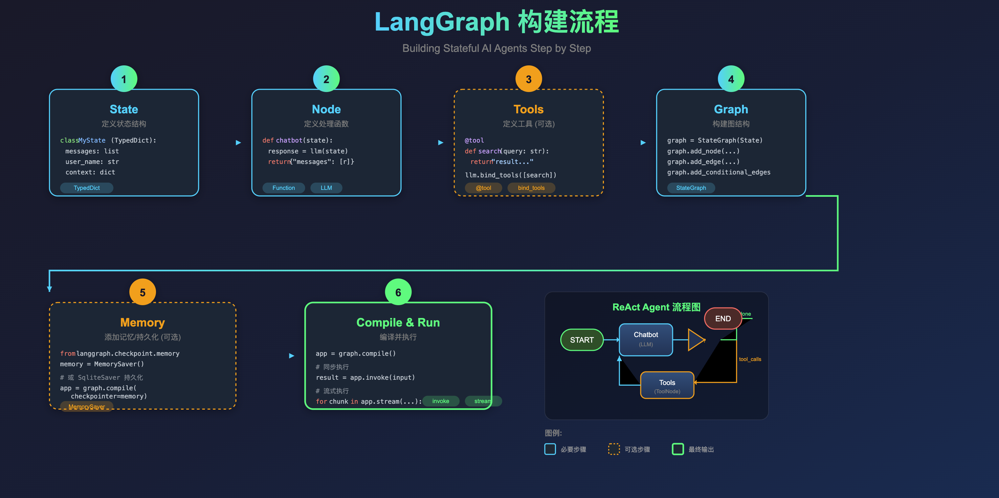

# 二、Text2sql

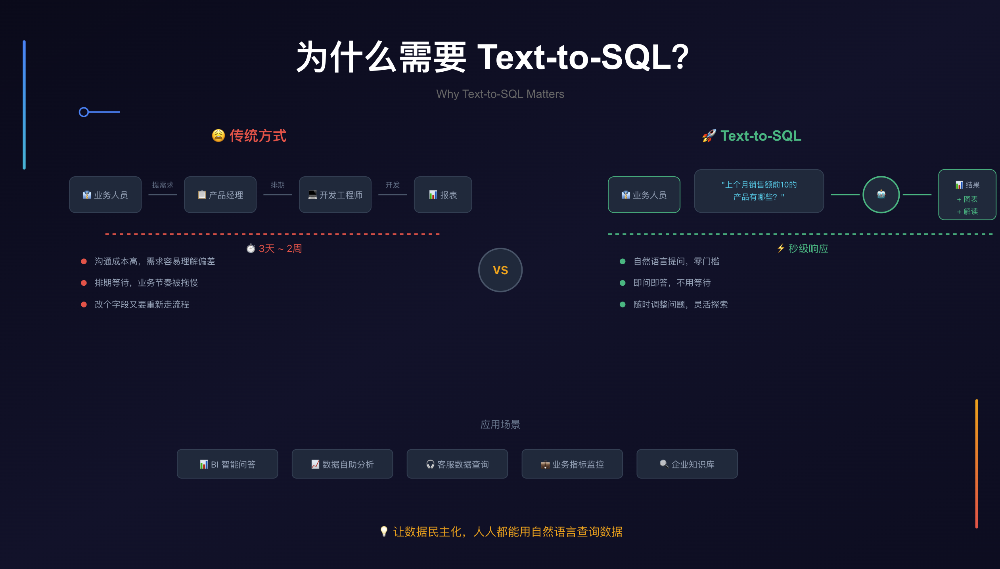

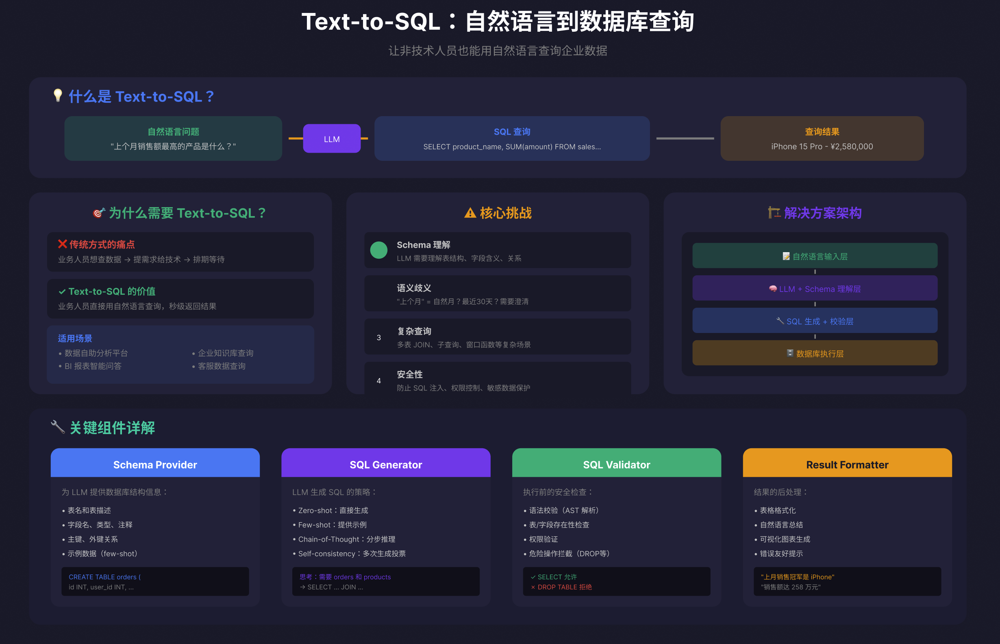

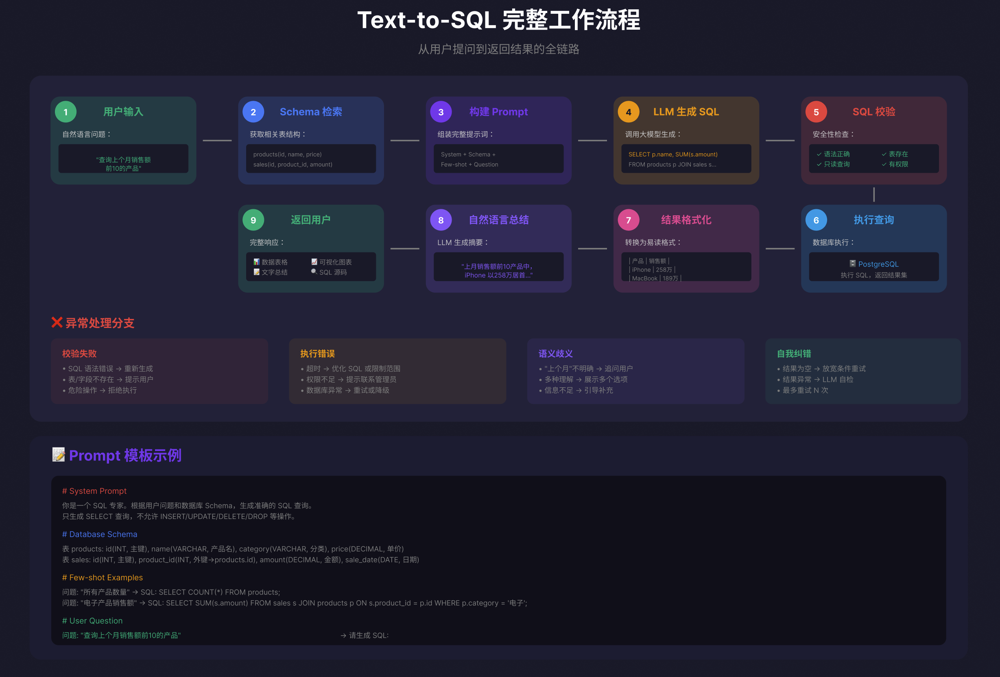

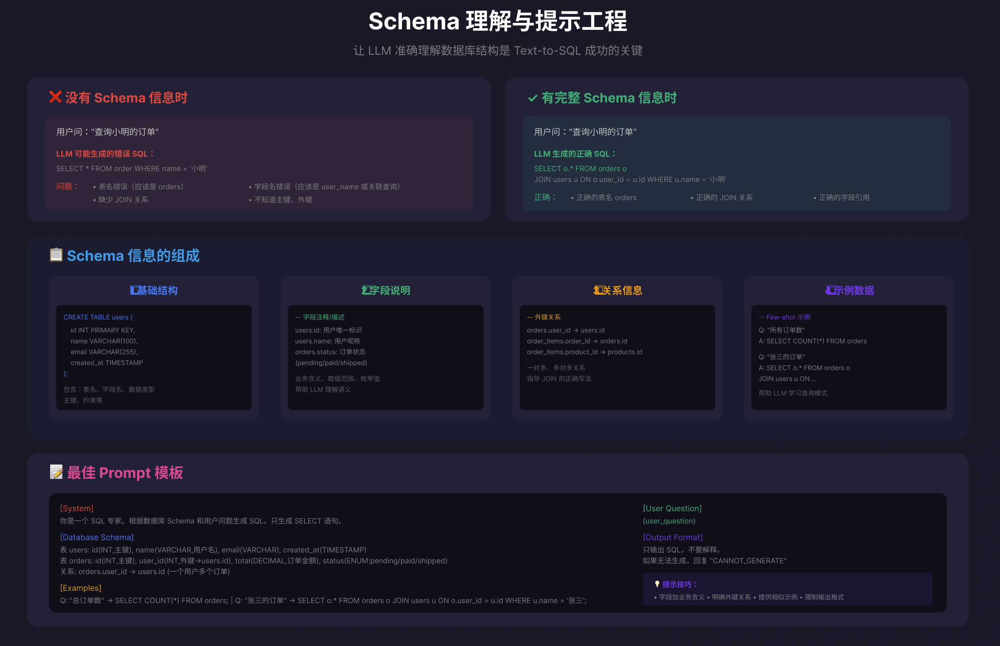

# Text2SQL 中的 JOIN 关系解析

## 一、什么是 JOIN？

JOIN 是 SQL 中用于**将两个或多个表根据关联条件组合在一起**的操作。当数据分散在多个表中时，我们需要通过 JOIN 来获取完整的信息。

### 举例说明

假设有两个表：

**学生表 (students)**
| student_id | name | class_id |
|------------|------|----------|
| 1 | 张三 | 101 |
| 2 | 李四 | 102 |

**班级表 (classes)**
| class_id | class_name | teacher |
|----------|------------|---------|
| 101 | 高一1班 | 王老师 |
| 102 | 高一2班 | 李老师 |

当用户问："**张三的班主任是谁？**"

这个问题需要跨两个表查询：
- 从 `students` 表找到张三的 `class_id`
- 从 `classes` 表找到对应的 `teacher`

对应的 SQL：
```sql
SELECT c.teacher 
FROM students s 
JOIN classes c ON s.class_id = c.class_id 
WHERE s.name = '张三';
```

---

## 二、Text2SQL 如何解决 JOIN 关系？

Text2SQL 系统解决 JOIN 问题主要通过以下几个关键步骤：

### 1. Schema 理解与建模

系统首先需要理解数据库的结构：
- **表结构**：有哪些表，每个表有哪些列
- **主键/外键关系**：表之间通过哪些字段关联
- **语义信息**：列名、表名的含义

通常会构建一个 **Schema Graph（模式图）**，将表作为节点，外键关系作为边。

### 2. 实体识别与表映射

当用户输入自然语言问题时，系统需要：

| 用户表述 | 映射结果 |
|---------|---------|
| "张三" | students.name |
| "班主任" | classes.teacher |

系统识别出问题涉及多个表，就知道需要 JOIN。

### 3. JOIN 路径推理

这是核心难点。常见的解决方案包括：

**a) 基于图的路径搜索**
- 在 Schema Graph 上找两个表之间的最短路径
- 路径上的边就是 JOIN 条件

```
students --[class_id]--> classes
```

**b) 基于神经网络的关系预测**
- 使用 GNN（图神经网络）学习表之间的关联
- 模型预测哪些表需要 JOIN，以及 JOIN 条件

**c) 基于大语言模型的推理**
- 现代 LLM 方法（如基于 GPT/Claude）直接将 schema 信息和问题一起输入
- 模型通过上下文理解推断出正确的 JOIN 关系

### 4. 典型模型的处理方式

| 模型类型 | JOIN 处理方法 |
|---------|--------------|
| **Spider/SParC 基准模型** | 使用 Schema Linking + Graph Encoder |
| **RAT-SQL** | 关系感知的 Transformer，显式建模表-列-问题之间的关系 |
| **BRIDGE** | 结合 Schema 和问题的联合编码 |
| **ChatGPT/Claude 等 LLM** | 通过 Prompt 提供 Schema 信息，利用推理能力生成 JOIN |

### 5. 一个完整的处理流程示例

用户问题："**列出所有销售额超过100万的门店经理姓名**"

```
步骤1: 实体识别
  - "销售额" → sales.amount
  - "门店" → stores
  - "经理姓名" → managers.name

步骤2: 发现涉及3个表，需要JOIN

步骤3: 查找外键关系
  - stores.manager_id → managers.id
  - sales.store_id → stores.id

步骤4: 生成SQL
SELECT m.name 
FROM managers m
JOIN stores s ON m.id = s.manager_id
JOIN sales sa ON s.id = sa.store_id
GROUP BY m.name
HAVING SUM(sa.amount) > 1000000;
```

---

## 三、主要挑战

1. **多跳 JOIN**：问题涉及多个中间表时，路径选择困难
2. **歧义消解**：多条可能的 JOIN 路径，需要选择语义正确的
3. **隐式关系**：用户没有明确提到某些表，但逻辑上必须经过
4. **自连接**：同一张表需要 JOIN 自己的情况


# SQL JOIN 语句逐句解析

## 原始 SQL 语句

```sql
SELECT c.teacher 
FROM students s 
JOIN classes c ON s.class_id = c.class_id 
WHERE s.name = '张三';
```

让我逐行解释：

---

## 1. `FROM students s`

**含义**：从 `students` 表开始查询，并给它起一个**别名** `s`

- `students` 是表名
- `s` 是别名（alias），后面可以用 `s` 代替 `students`，写起来更简洁

相当于说："我要查学生表，后面我就叫它 s 了"

---

## 2. `JOIN classes c ON s.class_id = c.class_id`

**含义**：把 `classes` 表（别名 `c`）连接进来，连接条件是两个表的 `class_id` 相等

拆解来看：

| 部分 | 含义 |
|------|------|
| `JOIN classes c` | 连接 classes 表，别名为 c |
| `ON` | 后面跟连接条件 |
| `s.class_id = c.class_id` | 当学生表的 class_id 等于班级表的 class_id 时，把这两行数据合并 |

**连接后的效果**：

| student_id | name | class_id | class_id | class_name | teacher |
|------------|------|----------|----------|------------|---------|
| 1 | 张三 | 101 | 101 | 高一1班 | 王老师 |
| 2 | 李四 | 102 | 102 | 高一2班 | 李老师 |

---

## 3. `WHERE s.name = '张三'`

**含义**：筛选条件——只保留学生姓名等于"张三"的行

过滤后只剩：

| student_id | name | class_id | class_id | class_name | teacher |
|------------|------|----------|----------|------------|---------|
| 1 | 张三 | 101 | 101 | 高一1班 | 王老师 |

---

## 4. `SELECT c.teacher`

**含义**：从结果中只取出 `classes` 表的 `teacher` 列

最终结果：

| teacher |
|---------|
| 王老师 |

---

## 执行顺序总结

SQL 的**实际执行顺序**（不是书写顺序）：

```
1. FROM students s          -- 先确定主表
2. JOIN classes c ON ...    -- 连接其他表
3. WHERE s.name = '张三'    -- 过滤数据
4. SELECT c.teacher         -- 选择要显示的列
```

---

## 用生活类比

想象你在图书馆查资料：

1. **FROM** → 先拿出"学生登记本"
2. **JOIN** → 再拿出"班级花名册"，把同一个班级号的信息对齐放在一起
3. **WHERE** → 只看名字叫"张三"那一行
4. **SELECT** → 只抄下"班主任"这一栏的内容

最终你得到了答案：**王老师**

# 三、代码执行器

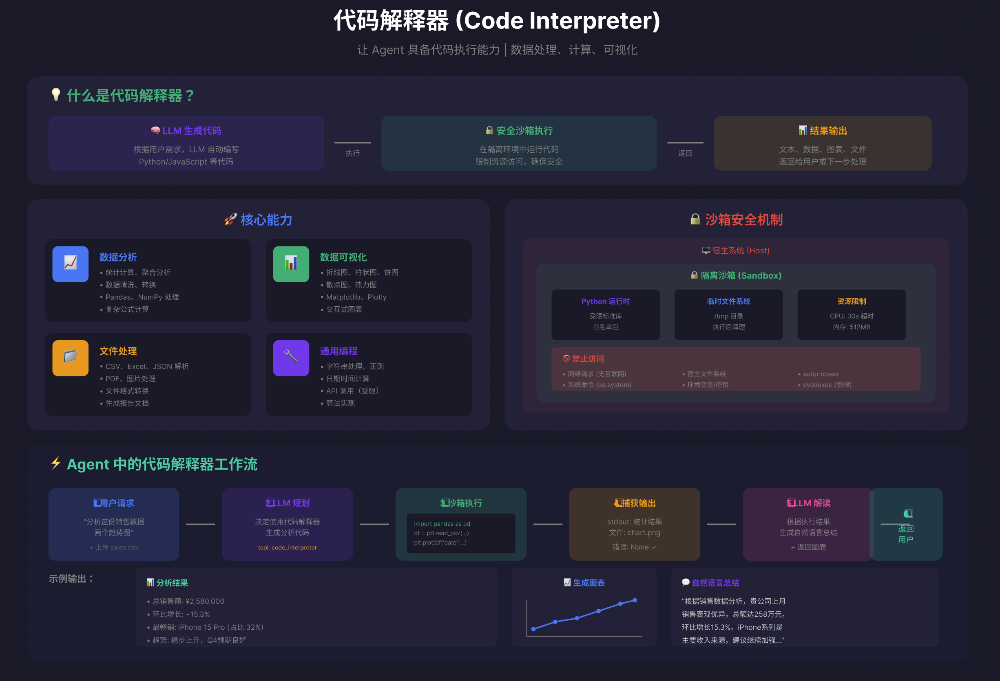

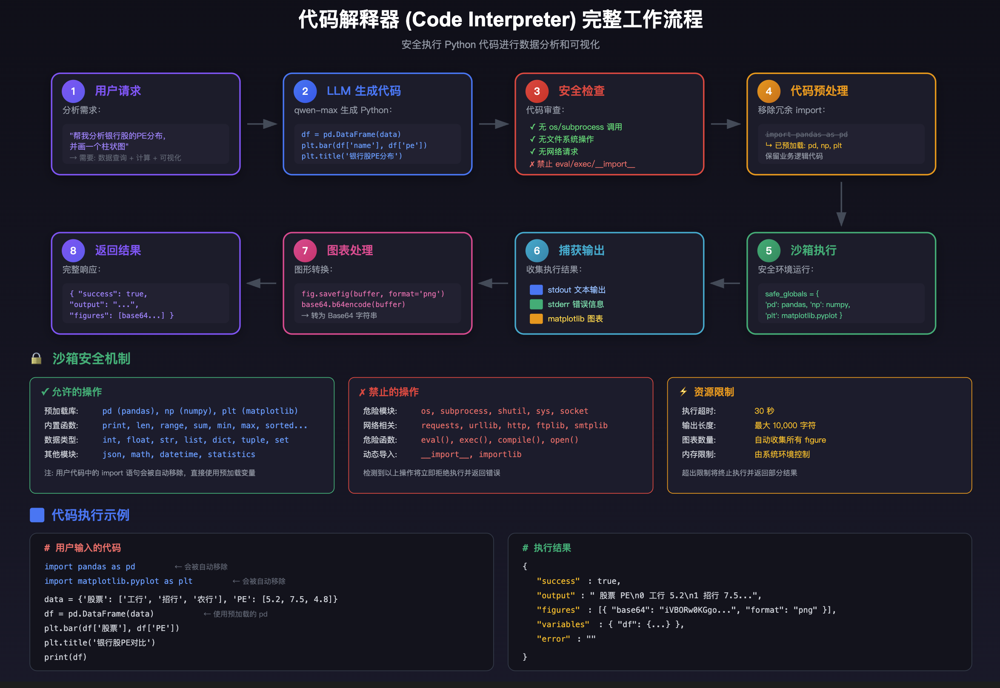

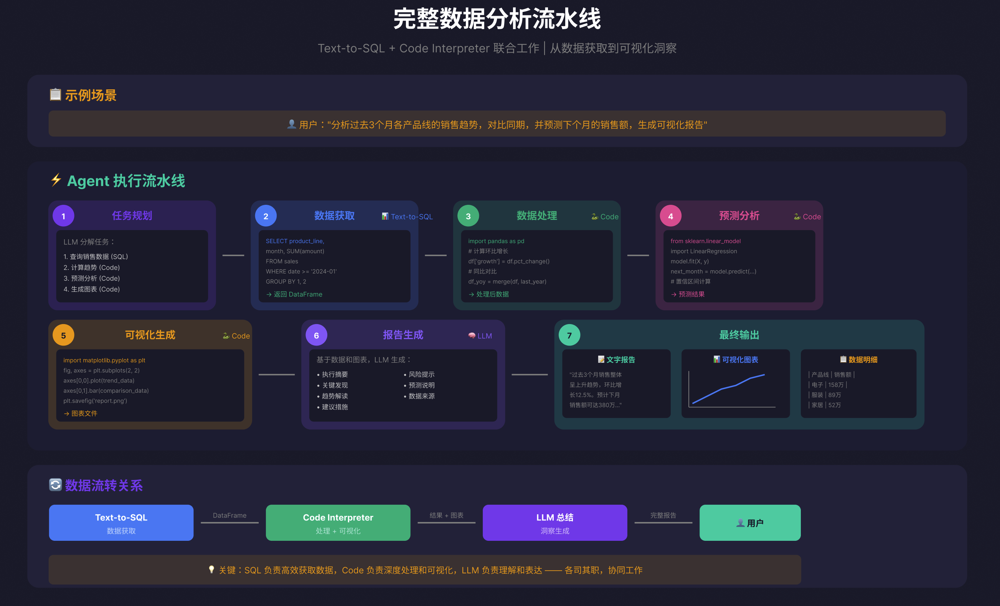